In [22]:
%pip install -q torch pennylane numpy pandas scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [23]:
import sys, subprocess

def _pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

try:
    import pennylane as qml
except ImportError:
    print("PennyLane not found — installing...")
    _pip_install("pennylane")
    import pennylane as qml

print("PennyLane version:", qml.__version__)


PennyLane version: 0.42.3


## 1

In [24]:
import os
import re
import time
import json
import math
import random
import warnings
from dataclasses import dataclass, field

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils import weight_norm

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['font.size'] = 11

warnings.filterwarnings("ignore")

import pennylane as qml

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Torch version: 2.5.1+cu121
CUDA available: True


In [25]:
# NEW (comparison): extra imports needed for the expanded model-comparison suite
# (Persistence / SVR / RF / LSTM / GRU / Transformer / TCN / VQC / TCN-VQC).
from dataclasses import replace
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor


## 2. Configuration

In [26]:
@dataclass
class Config:
    # --- Data location ---
    # Point this at the single merged CSV (blockwise SCADA + weather export). If left as-is,
    # the loader searches a handful of common locations for a plausibly-matching CSV.
    data_path: str = "C:\\Users\\VICTUS\\OneDrive\\Desktop\\TCN-VQC_Model\\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv"
    extra_search_dirs: tuple = (".", "./data", "../data", "/mnt/user-data/uploads")

    # --- Column schema (canonical names; loader fuzzy-matches your file's headers to these) ---
    target_col: str = "Actual"
    # CHANGED (v3): raw physical columns (read from the CSV) kept separate from engineered
    # (computed) ones, so the loader's column-presence check only requires what's actually
    # in the file.
    raw_feature_cols: tuple = (
        "Ambient Temperature", "Module Temperature", "Humidity Relative", "Wind Speed",
        "Wind Direction", "Air Pressure", "Available Capacity",
        "Radiation GHI", "Radiation GII", "Actual",
    )
    # NEW (v3): explicit sin/cos time-of-day clock signal. The model previously had to infer
    # exactly where sunrise/sunset falls from irradiance/temperature alone; giving it the clock
    # directly sharpens predictions right where MAPE is worst (the low-power shoulders).
    engineered_cols: tuple = ("TOD_sin", "TOD_cos")
    time_step_minutes: int = 15  # native resolution of the data (96 blocks / day)

    @property
    def feature_cols(self) -> tuple:
        # Full model input set = raw (from CSV) + engineered (computed). Kept as a property so
        # every other cell's `CFG.feature_cols` keeps working unchanged as a 12-element tuple.
        return self.raw_feature_cols + self.engineered_cols

    # --- Windowing ---
    lookback_hours: float = 24.0
    horizon_steps: int = 1  # 1 step ahead = 15 minutes ahead at native resolution

    # --- Split (chronological, no shuffling — see Section 1 for reasoning) ---
    train_frac: float = 0.70
    val_frac: float = 0.15  
    # remaining ~0.15 is test

    # --- Training (identical across every trained model) ---
    epochs: int = 50
    batch_size: int = 64
    lr: float = 1e-3
    weight_decay: float = 1e-5
    patience: int = 15          # the VQC head needs a few more epochs to find its footing
    grad_clip_norm: float = 1.0  # quantum-circuit gradients can spike; clip for stability
    lr_patience: int = 4         # epochs of no val-loss improvement before halving the LR
    lr_factor: float = 0.5       # LR reduction factor for the scheduler

    # NEW (v3): hybrid-loss knobs — see Section 12 (train_model / make_hybrid_loss).
    mape_loss_weight: float = 0.6   # relative weight of the MAPE-style term vs. MSE
    mape_eps_mw: float = 1.0        # same threshold as compute_metrics' MAPE mask (Actual > 1 MW)

    # --- TCN architecture ---
    tcn_channels: tuple = (32, 32, 32, 32)
    tcn_kernel_size: int = 5
    tcn_dropout: float = 0.1

    # --- Quantum head ---
    n_qubits: int = 6   # a bit more room for the circuit to represent the residual
    q_layers: int = 4   # more entangling layers, paired with StronglyEntanglingLayers

    # --- Misc ---
    seed: int = 42
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    out_dir: str = "./outputs_power"

    @property
    def seq_len(self) -> int:
        steps_per_hour = 60 / self.time_step_minutes
        return int(round(self.lookback_hours * steps_per_hour))


CFG = Config()
os.makedirs(CFG.out_dir, exist_ok=True)
for sub in ["predictions", "metrics", "plots"]:
    os.makedirs(os.path.join(CFG.out_dir, sub), exist_ok=True)


def set_seed(seed: int = CFG.seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CFG.seed)
DEVICE = torch.device(CFG.device)
print("Using device:", DEVICE)
print(f"seq_len = {CFG.seq_len} steps  ({CFG.lookback_hours}h @ {CFG.time_step_minutes}-min resolution)")
print(f"horizon = {CFG.horizon_steps} step(s) = {CFG.horizon_steps * CFG.time_step_minutes} minutes ahead")
print(f"Split: train={CFG.train_frac:.0%}  val={CFG.val_frac:.0%}  test={1 - CFG.train_frac - CFG.val_frac:.0%}")
print(f"Feature columns ({len(CFG.feature_cols)}): {CFG.feature_cols}")


Using device: cuda
seq_len = 96 steps  (24.0h @ 15-min resolution)
horizon = 1 step(s) = 15 minutes ahead
Split: train=70%  val=15%  test=15%
Feature columns (12): ('Ambient Temperature', 'Module Temperature', 'Humidity Relative', 'Wind Speed', 'Wind Direction', 'Air Pressure', 'Available Capacity', 'Radiation GHI', 'Radiation GII', 'Actual', 'TOD_sin', 'TOD_cos')


## 3. Data Loading

The reference notebook loaded three yearly NSRDB CSVs and fuzzy-matched each file's headers to
a canonical schema. Here there is only **one** file — a full year (Apr-2021 → Apr-2022) of
15-minute blockwise SCADA + weather data for a solar plant — but its headers are messier
(typos such as `Humidty\nRelative`, `WInd \nDirection`, embedded newlines, inconsistent
capitalization), so the same tolerant fuzzy-matching approach is kept and is, if anything, more
useful here. The loader normalizes whitespace in every header and maps each raw column to a
canonical name regardless of exact wording, then searches a handful of common locations for the
CSV if the configured path isn't found directly.

In [27]:
# Canonical name -> lowercase keyword(s) used to recognize a column regardless of exact wording
_COLUMN_ALIASES = {
    "Date": ["date"],
    "Time": ["time"],
    "Available Capacity": ["available capacity"],
    "Actual": ["actual"],
    "Radiation GHI": ["radiation ghi"],
    "Radiation GII": ["radiation gii"],
    "Wind Speed": ["wind speed"],
    "Wind Direction": ["wind direction"],
    "Humidity Relative": ["humidty relative", "humidity relative", "relative humidity"],
    "Ambient Temperature": ["ambient temperature"],
    "Module Temperature": ["module temperature"],
    "Air Pressure": ["air pressure"],
}


def _normalize_header(raw) -> str:
    # collapse embedded newlines / repeated whitespace (e.g. "WInd \nDirection") to single spaces
    return re.sub(r"\s+", " ", str(raw)).strip().lower()


def _map_columns(raw_columns) -> dict:
    mapping = {}
    used_canonical = set()
    for raw in raw_columns:
        key = _normalize_header(raw)
        for canonical, aliases in _COLUMN_ALIASES.items():
            if canonical in used_canonical:
                continue
            if any(alias == key or alias in key for alias in aliases):
                mapping[raw] = canonical
                used_canonical.add(canonical)
                break
    return mapping


def _find_csv() -> str:
    if os.path.isfile(CFG.data_path):
        return CFG.data_path

    search_dirs = list(CFG.extra_search_dirs)
    name_hints = ("merged", "blockwise", "weather", "actual")

    exact_matches, hinted_matches, any_matches = [], [], []
    for base in search_dirs:
        if not os.path.isdir(base):
            continue
        for root, _dirs, files in os.walk(base):
            for fname in files:
                if not fname.lower().endswith(".csv"):
                    continue
                full_path = os.path.join(root, fname)
                fname_lower = fname.lower()
                if fname_lower == os.path.basename(CFG.data_path).lower():
                    exact_matches.append(full_path)
                elif any(h in fname_lower for h in name_hints):
                    hinted_matches.append(full_path)
                else:
                    any_matches.append(full_path)

    for candidates in (exact_matches, hinted_matches, any_matches):
        if candidates:
            return sorted(candidates, key=len)[0]

    raise FileNotFoundError(
        f"Could not locate the merged power+weather CSV under {search_dirs}. "
        f"Set CFG.data_path to its exact location."
    )


def load_power_csv() -> pd.DataFrame:
    path = _find_csv()
    df = pd.read_csv(path)
    df.columns = [str(c) for c in df.columns]

    col_map = _map_columns(df.columns)
    # CHANGED (v3): only the raw physical columns need to exist in the file — TOD_sin/TOD_cos
    # are computed later in sort_and_clean(), not read from the CSV.
    required = {"Date", "Time"} | set(CFG.raw_feature_cols) | {CFG.target_col}
    missing_canonical = required - set(col_map.values())
    if missing_canonical:
        raise ValueError(
            f"Could not identify these required columns in {path}: {sorted(missing_canonical)}. "
            f"Found raw columns: {list(df.columns)}"
        )

    df = df.rename(columns=col_map)
    # CHANGED (v3): keep only raw columns here; engineered columns get added in sort_and_clean()
    keep_cols = ["Date", "Time"] + list(dict.fromkeys(CFG.raw_feature_cols))
    df = df[keep_cols]
    print(f"Loaded {path}  ->  shape={df.shape}")
    return df


# Preview
_preview_df = load_power_csv()
_preview_df.head()


Loaded C:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv  ->  shape=(35136, 12)


,Date,Time,Ambient Temperature,Module Temperature,Humidity Relative,Wind Speed,Wind Direction,Air Pressure,Available Capacity,Radiation GHI,Radiation GII,Actual
0,01-04-2021,0:00:00,28.242667,48.014667,39.852667,3.530667,38.700000,1001.926667,0.0,0.0,-3.0,0.0
1,01-04-2021,0:15:00,27.917333,47.460000,41.927333,3.732000,39.650000,1001.826667,0.0,0.0,-3.0,0.0
2,01-04-2021,0:30:00,27.602143,46.915000,43.854286,3.713571,39.446429,1001.721429,0.0,0.0,-3.0,0.0
3,01-04-2021,0:45:00,27.501333,46.750000,45.454667,2.276667,38.483333,1001.686667,0.0,0.0,-3.0,0.0
4,01-04-2021,1:00:00,27.276000,46.372000,46.680667,2.099333,39.616667,1001.580000,0.0,0.0,-3.0,0.0


## 4. Data Cleaning, Windowing & Chronological Split

The reference notebook's "combine years" step concatenated three yearly files into one
continuous chronological series. There is only one file here, so that step reduces to loading
plus the same sort/clean routine: parse timestamps, drop duplicate timestamps, and linearly
interpolate the small number of missing weather readings (132 of 35,136 blocks — about 0.4% —
have missing weather values; `Actual` itself has none missing). This year's data turns out to be
a perfectly regular 15-minute series with **zero real timestamp gaps**, but the gap-aware window
builder from the reference notebook is kept unchanged regardless — it only builds a window when
every step inside it is exactly 15 minutes apart from the next, which transparently guards
against any gap that might appear in the file (sensor downtime, missing rows) rather than
silently bridging across one.

Sequences are then split **chronologically** — train is the earliest 70% of the year, validation
the next 15%, and test the most recent 15% — exactly like the reference notebook's train → val →
test ordering, just with the different split fractions explained in Section 1. A small amount of
left-context is included right at each split boundary purely so that windows starting at the
boundary still have a full lookback of *past* data available; it is never allowed to pull in data
from *after* the boundary, so there is no leakage from validation into training or from test into
either.

In [28]:
def sort_and_clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["__timestamp"] = pd.to_datetime(df["Date"] + " " + df["Time"], dayfirst=True)
    df = df.sort_values("__timestamp").drop_duplicates(subset="__timestamp").reset_index(drop=True)

    # NEW (v3): cyclical time-of-day features. sin/cos of the fraction of the day elapsed gives
    # the model an explicit, noise-free clock signal — this pins down the exact sunrise/sunset
    # ramp boundary, which is where MAPE was worst (low absolute power, so any error there gets
    # amplified into a large relative error).
    seconds_of_day = (
        df["__timestamp"].dt.hour * 3600
        + df["__timestamp"].dt.minute * 60
        + df["__timestamp"].dt.second
    )
    frac_of_day = seconds_of_day / 86400.0
    df["TOD_sin"] = np.sin(2 * np.pi * frac_of_day)
    df["TOD_cos"] = np.cos(2 * np.pi * frac_of_day)

    needed = list(CFG.feature_cols)  # CHANGED (v3): now raw + engineered (12 columns)
    df[needed] = df[needed].apply(pd.to_numeric, errors="coerce")
    df[needed] = df[needed].interpolate(method="linear", limit_direction="both")
    df[needed] = df[needed].ffill().bfill()

    df["Month"] = df["__timestamp"].dt.month
    return df


def load_combined_dataset() -> pd.DataFrame:
    # Only one file here (vs. three yearly files in the reference notebook), so "combining"
    # reduces to loading plus the chronological sort/clean of that single continuous series.
    raw = load_power_csv()
    return sort_and_clean(raw)


RAW_DF = load_combined_dataset()
print("Combined dataset shape:", RAW_DF.shape)
print("Date range:", RAW_DF["__timestamp"].min(), "to", RAW_DF["__timestamp"].max())
RAW_DF[list(CFG.feature_cols)].describe().T


Loaded C:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv  ->  shape=(35136, 12)
Combined dataset shape: (35041, 16)
Date range: 2021-04-01 00:00:00 to 2022-03-31 23:45:00


,count,mean,std,min,25%,50%,75%,max
Ambient Temperature,35041.0,24.971458,10.606621,0.000000,22.468667,2.766000e+01,31.269231,42.232143
Module Temperature,35041.0,31.405191,21.902909,0.000000,14.036667,3.150867e+01,50.108000,71.796429
Humidity Relative,35041.0,50.166875,29.590751,0.000000,26.533333,5.300267e+01,74.806667,100.482000
Wind Speed,35041.0,2.965470,3.696087,0.000000,1.786667,2.364667e+00,3.282667,44.250000
Wind Direction,35041.0,27.860949,8.746756,0.000000,22.844000,2.696800e+01,34.616667,165.058667
Air Pressure,35041.0,886.237275,323.476101,0.000000,999.066667,1.003380e+03,1008.366667,1019.873333
Available Capacity,35041.0,152.140350,142.399175,0.000000,0.000000,2.500000e+02,300.000000,300.000000
Radiation GHI,35041.0,215.541274,303.987680,0.000000,0.000000,0.000000e+00,414.000000,1102.133333
Radiation GII,35041.0,233.247453,321.326715,-14.466667,0.000000,9.800000e+00,456.000000,1092.266667
Actual,35041.0,57.476646,85.835367,0.000000,0.000000,7.200000e-02,92.088000,313.704000


In [29]:
def create_sequences_gap_aware(features: np.ndarray, target: np.ndarray, timestamps: pd.Series,
                                seq_len: int, horizon: int, step_minutes: int) -> tuple:
    """Builds sliding windows, skipping any window whose span isn't perfectly regular
    (i.e. would silently bridge a real gap in the SCADA/weather record)."""
    n = len(features)
    expected_span = pd.Timedelta(minutes=step_minutes * (seq_len + horizon - 1))
    ts = timestamps.values

    X, y, idx_kept = [], [], []
    last_start = n - seq_len - horizon + 1
    for i in range(last_start):
        span = ts[i + seq_len + horizon - 1] - ts[i]
        if span != np.timedelta64(expected_span):
            continue  # a real gap exists inside this window; skip it rather than mis-align
        X.append(features[i: i + seq_len])
        y.append(target[i + seq_len + horizon - 1])
        idx_kept.append(i)

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32), np.asarray(idx_kept)


def prepare_data(df: pd.DataFrame, cfg: Config = CFG):
    feat_df = df[list(cfg.feature_cols)]
    target_series = df[cfg.target_col].values.astype(np.float32)
    timestamps = df["__timestamp"]

    n = len(df)
    train_end = int(n * cfg.train_frac)
    val_end = int(n * (cfg.train_frac + cfg.val_frac))

    feature_scaler = MinMaxScaler()
    target_scaler = MinMaxScaler()
    feature_scaler.fit(feat_df.iloc[:train_end].values)
    target_scaler.fit(target_series[:train_end].reshape(-1, 1))

    features_scaled = feature_scaler.transform(feat_df.values)
    target_scaled = target_scaler.transform(target_series.reshape(-1, 1)).ravel()

    seq_len, horizon = cfg.seq_len, cfg.horizon_steps

    def window_slice(lo, hi):
        # include seq_len+horizon-1 steps of left-context so windows starting right at the
        # split boundary are still valid (context only — never crosses into label leakage)
        ctx_lo = max(0, lo - (seq_len + horizon - 1))
        feats = features_scaled[ctx_lo:hi]
        targ = target_scaled[ctx_lo:hi]
        ts = timestamps.iloc[ctx_lo:hi].reset_index(drop=True)
        X, y, _ = create_sequences_gap_aware(feats, targ, ts, seq_len, horizon, cfg.time_step_minutes)
        return X, y

    X_train, y_train = window_slice(0, train_end)
    X_val, y_val = window_slice(train_end, val_end)
    X_test, y_test = window_slice(val_end, n)

    # also keep per-month test masks for the month-level breakdown later (a single year of
    # data is available, so a per-year breakdown as in the reference notebook would not be
    # meaningful here — see Section 15)
    _, _, kept_idx = create_sequences_gap_aware(
        features_scaled[max(0, val_end - (seq_len + horizon - 1)):n],
        target_scaled[max(0, val_end - (seq_len + horizon - 1)):n],
        timestamps.iloc[max(0, val_end - (seq_len + horizon - 1)):n].reset_index(drop=True),
        seq_len, horizon, cfg.time_step_minutes,
    )
    ctx_lo = max(0, val_end - (seq_len + horizon - 1))
    target_positions = ctx_lo + kept_idx + seq_len + horizon - 1
    test_months_aligned = df["Month"].values[target_positions]

    return {
        "X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test, "y_test": y_test,
        "test_months": test_months_aligned,
        "feature_scaler": feature_scaler,
        "target_scaler": target_scaler,
        "n_features": len(cfg.feature_cols),
        "feature_names": list(cfg.feature_cols),
    }


DATA = prepare_data(RAW_DF, CFG)
print(f"Train windows: {len(DATA['X_train'])}  |  Val: {len(DATA['X_val'])}  |  Test: {len(DATA['X_test'])}")
print(f"Test windows by month: { {int(m): int((DATA['test_months']==m).sum()) for m in sorted(np.unique(DATA['test_months']))} }")


Train windows: 24432  |  Val: 5256  |  Test: 5256
Test windows by month: {2: 2280, 3: 2976}


## 5. PyTorch Dataset & DataLoaders

In [30]:
class WindowDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float().unsqueeze(-1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_loaders(data: dict, batch_size: int = CFG.batch_size):
    train_ds = WindowDataset(data["X_train"], data["y_train"])
    val_ds = WindowDataset(data["X_val"], data["y_val"])
    test_ds = WindowDataset(data["X_test"], data["y_test"])
    return (
        DataLoader(train_ds, batch_size=batch_size, shuffle=False),
        DataLoader(val_ds, batch_size=batch_size, shuffle=False),
        DataLoader(test_ds, batch_size=batch_size, shuffle=False),
    )


train_loader, val_loader, test_loader = make_loaders(DATA)


## 6. Metrics & Utilities

In [31]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    mse = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # MAPE computed only over samples with meaningfully non-zero actual generation (avoids
    # division blow-up at night, when Actual power is ~0 by definition — roughly half of all
    # 15-minute blocks in this dataset are night-time zeros)
    mask = y_true > 1.0
    mape = (np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])).mean() * 100 if mask.any() else float("nan")
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2, "MAPE_%": mape}


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def inverse_scale(scaler: MinMaxScaler, arr: np.ndarray) -> np.ndarray:
    return scaler.inverse_transform(arr.reshape(-1, 1)).ravel()


## 7. Model 1 — Persistence Baseline (no training)

Predicts `Actual(t+horizon) = Actual(t)` — power output 15 minutes from now equals power output
right now. Exactly like the GHI persistence baseline in the reference notebook, this is the
classic hard-to-beat benchmark for short-horizon forecasting: any learned model should be judged
against this, not just against other learned models.

In [32]:
def persistence_predict(data: dict, cfg: Config = CFG) -> tuple:
    # last known (scaled) Actual power in each window is the last timestep's Actual feature
    actual_idx = cfg.feature_cols.index("Actual")
    X_test = data["X_test"]
    y_pred_scaled = X_test[:, -1, actual_idx]
    y_true_scaled = data["y_test"]
    y_pred = inverse_scale(data["target_scaler"], y_pred_scaled)
    y_true = inverse_scale(data["target_scaler"], y_true_scaled)
    y_pred = np.clip(y_pred, 0.0, None)  # NEW (v3): power output is physically non-negative
    return y_true, y_pred


## 8. Temporal Convolutional Network (TCN) Backbone



In [33]:
class Chomp1d(nn.Module):

    def __init__(self, chomp_size: int):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous() if self.chomp_size > 0 else x


class TemporalBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dilation: int, dropout: float):
        super().__init__()
        padding = (kernel_size - 1) * dilation

        self.conv1 = weight_norm(
            nn.Conv1d(in_ch, out_ch, kernel_size,
                      padding=padding, dilation=dilation)
        )
        self.chomp1 = Chomp1d(padding)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout)

        self.conv2 = weight_norm(
            nn.Conv1d(out_ch, out_ch, kernel_size,
                      padding=padding, dilation=dilation)
        )
        self.chomp2 = Chomp1d(padding)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout)

        self.net = nn.Sequential(
            self.conv1, self.chomp1, self.relu1, self.drop1,
            self.conv2, self.chomp2, self.relu2, self.drop2
        )

        self.downsample = (
            nn.Conv1d(in_ch, out_ch, 1)
            if in_ch != out_ch else None
        )

        self.relu_out = nn.ReLU()
        self._init_weights()

    def _init_weights(self):
        self.conv1.weight.data.normal_(0, 0.01)
        self.conv2.weight.data.normal_(0, 0.01)
        if self.downsample is not None:
            self.downsample.weight.data.normal_(0, 0.01)

    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu_out(out + res)


class TemporalConvNet(nn.Module):
    def __init__(self, n_features: int, channels: tuple,
                 kernel_size: int, dropout: float):
        super().__init__()

        layers = []
        for i, out_ch in enumerate(channels):
            dilation = 2 ** i
            in_ch = n_features if i == 0 else channels[i - 1]

            layers.append(
                TemporalBlock(
                    in_ch=in_ch,
                    out_ch=out_ch,
                    kernel_size=kernel_size,
                    dilation=dilation,
                    dropout=dropout,
                )
            )

        self.network = nn.Sequential(*layers)

        # Effective receptive field
        self.receptive_field = (
            1 + 2 * (kernel_size - 1) * sum(2 ** i for i in range(len(channels)))
        )

    def forward(self, x):
        # x: (batch, seq_len, features)
        x = x.transpose(1, 2)
        out = self.network(x)
        return out.transpose(1, 2)


# ------------------------------------------------------------------
# Check whether the TCN receptive field covers the entire input window
# ------------------------------------------------------------------

_tcn_probe = TemporalConvNet(
    len(CFG.feature_cols),
    CFG.tcn_channels,
    CFG.tcn_kernel_size,
    CFG.tcn_dropout,
)

status = (
    "covers full window ✓"
    if _tcn_probe.receptive_field >= CFG.seq_len
    else "DOES NOT cover full window - add more channels/layers!"
)

print(
    f"TCN receptive field: {_tcn_probe.receptive_field} steps "
    f"({_tcn_probe.receptive_field * CFG.time_step_minutes / 60:.1f} h) "
    f"vs. seq_len={CFG.seq_len} steps "
    f"({CFG.lookback_hours} h) -> {status}"
)

del _tcn_probe

TCN receptive field: 121 steps (30.2 h) vs. seq_len=96 steps (24.0 h) -> covers full window ✓


## 9. Variational Quantum Circuit (VQC) Head

Applied **once**, to the TCN's final pooled feature vector — not per-timestep — so its cost
is independent of sequence length. Uses the standard "dressed quantum circuit" pattern: a
trainable classical layer maps features down to `n_qubits` rotation angles, the quantum
circuit processes them, and a trainable classical layer maps the `n_qubits` expectation
values back up before the output head.

**Update:** the circuit was widened from 4 qubits / 2 layers of `BasicEntanglerLayers` to
**6 qubits / 4 layers of `StronglyEntanglingLayers`**. `StronglyEntanglingLayers` applies a full
set of arbitrary single-qubit rotations (not just one axis) plus entangling gates per layer, so
it can represent a substantially richer function of its inputs than `BasicEntanglerLayers` at the
same qubit count — the original circuit was likely too constrained to fit anything beyond a
coarse approximation of the target, which is consistent with the systematic amplitude-compression
seen at the solar peaks in the first run.

In [34]:
N_QUBITS = CFG.n_qubits
Q_LAYERS = CFG.q_layers


def make_vqc_torch_layer(n_qubits: int = N_QUBITS, q_layers: int = Q_LAYERS):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")
        # CHANGED: StronglyEntanglingLayers (3 rotation angles/wire/layer + entangling gates)
        # instead of BasicEntanglerLayers (1 rotation angle/wire/layer) — a richer, less
        # constrained circuit at the same qubit count.
        qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    # StronglyEntanglingLayers weight shape is (layers, wires, 3) vs. BasicEntanglerLayers' (layers, wires)
    weight_shapes = {"weights": (q_layers, n_qubits, 3)}
    return qml.qnn.TorchLayer(circuit, weight_shapes)


## 10. Model 2 — TCN (classical, no quantum head) — ablation control

**Update:** both this model and the TCN-VQC hybrid below now predict a **residual (delta) on
top of persistence** — `prediction = last_known_Actual + model_output` — instead of the absolute
power value directly. At a 15-minute horizon, `Actual` barely moves except at sunrise/sunset, so
asking the network to reconstruct the entire 0–300 MW curve from scratch wastes most of its
capacity on the "trivial" 95% that persistence already gets right. Learning only the correction
lets both models focus their capacity on the genuinely hard part (ramps, cloud transients), and
keeps the classical-vs-quantum comparison apples-to-apples since the same reformulation is
applied to both.

In [35]:
class TCNModel(nn.Module):
    """Classical control: identical backbone to TCN-VQC, but the quantum head is replaced
    by a classical linear layer of matching width. Used to isolate whether the VQC head
    contributes anything beyond what an equivalently-sized classical layer would."""

    def __init__(self, n_features: int, cfg: Config = CFG):
        super().__init__()
        self.actual_idx = cfg.feature_cols.index("Actual")  # NEW: for the residual/persistence term
        self.tcn = TemporalConvNet(n_features, cfg.tcn_channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        feat_dim = cfg.tcn_channels[-1]

        # Pre-net matches TCN-VQC's pre_net exactly (same width, same hidden layer) so the two
        # models differ only in what happens to the n_qubits-wide bottleneck representation.
        self.pre_net = nn.Sequential(
            nn.Linear(feat_dim, 16),
            nn.ReLU(),
            nn.Linear(16, cfg.n_qubits),
        )
        # Classical stand-in for the quantum circuit: same bottleneck width, one nonlinear mix,
        # analogous to what the entangling layers do to the rotation angles.
        self.classical_head = nn.Sequential(
            nn.Linear(cfg.n_qubits, cfg.n_qubits),
            nn.ReLU(),
        )
        self.post_net = nn.Linear(cfg.n_qubits, 1)
        nn.init.zeros_(self.post_net.bias)  # start near "predict zero correction" (i.e. persistence)

    def forward(self, x):
        last_val = x[:, -1, self.actual_idx].unsqueeze(-1)  # NEW: last known (scaled) Actual value
        tcn_out = self.tcn(x)          # (batch, seq_len, channels[-1])
        pooled = tcn_out[:, -1, :]     # last timestep already integrates the full causal receptive field
        angles = torch.tanh(self.pre_net(pooled)) * math.pi  # same bounding as the VQC path, for fairness
        h = self.classical_head(angles)
        delta = self.post_net(h)
        return last_val + delta        # NEW: residual/delta formulation

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


## 11. Model 3 — TCN + VQC Hybrid (main architecture)

Same residual/delta formulation as the classical control above: the quantum head now only has
to learn the *correction* on top of the last known power value, not the absolute curve. The
pre-net was also given a small hidden layer (`feat_dim -> 16 -> n_qubits`) instead of a single
linear projection, giving the network a bit more room to compress the TCN's 32-channel
representation down to the 6 rotation angles the circuit consumes.

In [36]:
class TCN_VQC_Model(nn.Module):
    def __init__(self, n_features: int, cfg: Config = CFG):
        super().__init__()
        self.actual_idx = cfg.feature_cols.index("Actual")  # NEW: for the residual/persistence term
        self.tcn = TemporalConvNet(n_features, cfg.tcn_channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        feat_dim = cfg.tcn_channels[-1]

        # CHANGED: added a hidden layer (was a single Linear) — more room to compress the TCN's
        # representation down to the n_qubits rotation angles.
        self.pre_net = nn.Sequential(
            nn.Linear(feat_dim, 16),
            nn.ReLU(),
            nn.Linear(16, cfg.n_qubits),
        )
        self.qlayer = make_vqc_torch_layer(cfg.n_qubits, cfg.q_layers)
        self.post_net = nn.Linear(cfg.n_qubits, 1)
        nn.init.zeros_(self.post_net.bias)  # start near "predict zero correction" (i.e. persistence)

    def forward(self, x):
        last_val = x[:, -1, self.actual_idx].unsqueeze(-1)  # NEW: last known (scaled) Actual value
        tcn_out = self.tcn(x)          # (batch, seq_len, channels[-1])
        pooled = tcn_out[:, -1, :]     # single feature vector per sample -> ONE quantum call per forward pass
        angles = torch.tanh(self.pre_net(pooled)) * math.pi  # bound rotation angles to [-pi, pi]
        q_out = self.qlayer(angles)
        delta = self.post_net(q_out)
        return last_val + delta        # NEW: residual/delta formulation

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


## 12. Training & Evaluation Routines
Adam, lr=1e-3, MSE loss, batch size 64, up to 50 epochs, early stopping with patience 15 on
validation loss (increased from 10 — the VQC head takes a little longer to settle).

**Update:** two stability additions, applied identically to every trained model so the
comparison stays fair:
- **Gradient clipping** (`max_norm=1.0`) — quantum-circuit gradients can spike, and clipping
  keeps a single bad batch from throwing off the optimizer.
- **`ReduceLROnPlateau` LR scheduler** — halves the learning rate after `lr_patience` epochs
  without validation-loss improvement, so training can keep making progress with smaller steps
  once it's in the neighborhood of a good solution, rather than stalling at a fixed LR.

In [37]:
def make_hybrid_loss(mape_weight: float, thresh_scaled: float):
    """NEW (v3): MSE (keeps training stable and gets the overall curve shape right) plus a
    relative-error term computed the same way compute_metrics() computes MAPE_% (masked to
    samples where the scaled target exceeds `thresh_scaled`, matching the `Actual > 1 MW` mask
    used at eval time). Training now directly optimizes the metric you're being judged on,
    instead of only MSE."""
    mse_fn = nn.MSELoss()

    def loss_fn(pred, true):
        mse = mse_fn(pred, true)
        mask = (true.abs() > thresh_scaled).float()
        denom = true.abs().clamp_min(thresh_scaled)
        rel_err = torch.abs(pred - true) / denom
        n_active = mask.sum()
        mape_term = (rel_err * mask).sum() / n_active if n_active > 0 else torch.zeros((), device=pred.device)
        return mse + mape_weight * mape_term

    return loss_fn


def train_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
                 cfg: Config = CFG, verbose: bool = False, criterion=None):
    model = model.to(cfg.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    criterion = criterion if criterion is not None else nn.MSELoss()  # CHANGED (v3): pluggable loss
    # halve the LR after `lr_patience` stagnant epochs, so training can keep refining
    # once it plateaus instead of stalling at a fixed step size.
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=cfg.lr_factor, patience=cfg.lr_patience
    )

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0
    history = {"train_loss": [], "val_loss": []}

    start_time = time.time()
    for epoch in range(cfg.epochs):
        model.train()
        running_loss, n_samples = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(cfg.device), yb.to(cfg.device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            # clip gradient norm before stepping — guards against quantum-circuit gradient spikes.
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.grad_clip_norm)
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            n_samples += xb.size(0)
        train_loss = running_loss / max(n_samples, 1)

        model.eval()
        val_running, val_n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(cfg.device), yb.to(cfg.device)
                preds = model(xb)
                val_running += criterion(preds, yb).item() * xb.size(0)
                val_n += xb.size(0)
        val_loss = val_running / max(val_n, 1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        scheduler.step(val_loss)

        if verbose:
            current_lr = optimizer.param_groups[0]["lr"]
            print(f"  epoch {epoch+1:02d}/{cfg.epochs}  train_loss={train_loss:.6f}  "
                  f"val_loss={val_loss:.6f}  lr={current_lr:.2e}")

        if val_loss < best_val_loss - 1e-8:
            best_val_loss = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= cfg.patience:
                if verbose:
                    print(f"  early stopping at epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, time.time() - start_time


def evaluate_model(model: nn.Module, test_loader: DataLoader, target_scaler: MinMaxScaler, cfg: Config = CFG):
    model = model.to(cfg.device)
    model.eval()
    all_preds, all_true = [], []
    start_time = time.time()
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(cfg.device)
            preds = model(xb)
            all_preds.append(preds.cpu().numpy())
            all_true.append(yb.numpy())
    inference_time = time.time() - start_time

    y_pred = inverse_scale(target_scaler, np.concatenate(all_preds).ravel())
    y_true = inverse_scale(target_scaler, np.concatenate(all_true).ravel())
    y_pred = np.clip(y_pred, 0.0, None)  # NEW (v3): power output is physically non-negative
    return y_true, y_pred, inference_time


## 13. Run All Models

In [38]:
RESULTS = {}       # name -> metrics dict
PREDICTIONS = {}   # name -> (y_true, y_pred)
HISTORIES = {}      # name -> training history (empty for persistence)

# NEW (comparison): records, per model, which feature set and training formulation it used —
# surfaced later in the results table so the comparison is transparent about *why* the
# proposed model has an advantage, per the evaluation protocol:
#   - Baselines: standard formulation, minimal fixed feature set (Actual + Radiation GHI only)
#   - Proposed (TCN-VQC): full architecture + training strategy + expanded feature set
#     (all 10 raw covariates + deterministic future-known TOD_sin/TOD_cos)
METRIC_META = {}

n_features = DATA["n_features"]

# NEW (v3): scaled threshold matching compute_metrics()'s `Actual > 1 MW` MAPE mask, and the
# hybrid loss built from it. Applied to BOTH TCN and TCN-VQC so the classical-vs-quantum
# ablation stays apples-to-apples (same principle the notebook already follows elsewhere).
_thresh_scaled = CFG.mape_eps_mw / DATA["target_scaler"].data_max_[0]
HYBRID_LOSS = make_hybrid_loss(CFG.mape_loss_weight, _thresh_scaled)
print(f"Hybrid loss: MSE + {CFG.mape_loss_weight} x relative-error "
      f"(scaled threshold={_thresh_scaled:.5f}, i.e. Actual > {CFG.mape_eps_mw} MW)")

# --- 1. Persistence baseline ---
print("--- Persistence baseline ---")
y_true, y_pred = persistence_predict(DATA, CFG)
metrics = compute_metrics(y_true, y_pred)
metrics.update({"Training_Time_s": 0.0, "Inference_Time_s": 0.0, "Num_Params": 0})
RESULTS["Persistence"] = metrics
PREDICTIONS["Persistence"] = (y_true, y_pred)
HISTORIES["Persistence"] = {"train_loss": [], "val_loss": []}
METRIC_META["Persistence"] = {"Feature_Set": "N/A (naive carry-forward)", "Formulation": "Standard"}
print(f"  RMSE={metrics['RMSE']:.4f}  MAE={metrics['MAE']:.4f}  R2={metrics['R2']:.4f}")

# --- 2. TCN — ALSO used below as the full-feature ablation control for the proposed model ---
# NOTE: unlike the "TCN" entry in the baseline-comparison suite (Section 13d, trained on the
# minimal feature set with a standard absolute-value formulation), THIS TCN uses the proposed
# model's full feature set and residual/hybrid-loss training strategy. It exists purely to
# isolate the quantum head's contribution (Section 14's ablation check) and is kept separate
# from the main model-comparison table.
print("\n--- Training TCN (classical, full-feature ablation control) ---")
set_seed(CFG.seed)
tcn_model = TCNModel(n_features, CFG)
tcn_model, hist, train_time = train_model(
    tcn_model, train_loader, val_loader, CFG, verbose=False, criterion=HYBRID_LOSS  # CHANGED (v3)
)
y_true, y_pred, inf_time = evaluate_model(tcn_model, test_loader, DATA["target_scaler"], CFG)
metrics = compute_metrics(y_true, y_pred)
metrics.update({"Training_Time_s": train_time, "Inference_Time_s": inf_time, "Num_Params": count_parameters(tcn_model)})
ABLATION_RESULTS = {}       # NEW (comparison): kept separate from RESULTS/METRICS_DF
ABLATION_PREDICTIONS = {}
ABLATION_RESULTS["TCN (full-feat, ablation)"] = metrics
ABLATION_PREDICTIONS["TCN (full-feat, ablation)"] = (y_true, y_pred)
print(f"  RMSE={metrics['RMSE']:.4f}  MAE={metrics['MAE']:.4f}  R2={metrics['R2']:.4f}  "
      f"train_time={train_time:.1f}s  params={metrics['Num_Params']}")

# --- 3. TCN + VQC (hybrid, main/proposed model) ---
print("\n--- Training TCN + VQC (hybrid, proposed model) ---")
set_seed(CFG.seed)
tcn_vqc_model = TCN_VQC_Model(n_features, CFG)
tcn_vqc_model, hist, train_time = train_model(
    tcn_vqc_model, train_loader, val_loader, CFG, verbose=False, criterion=HYBRID_LOSS  # CHANGED (v3)
)
y_true, y_pred, inf_time = evaluate_model(tcn_vqc_model, test_loader, DATA["target_scaler"], CFG)
metrics = compute_metrics(y_true, y_pred)
metrics.update({"Training_Time_s": train_time, "Inference_Time_s": inf_time, "Num_Params": count_parameters(tcn_vqc_model)})
RESULTS["TCN-VQC"] = metrics
PREDICTIONS["TCN-VQC"] = (y_true, y_pred)
HISTORIES["TCN-VQC"] = hist
METRIC_META["TCN-VQC"] = {
    "Feature_Set": "Full (10 covariates + TOD_sin/TOD_cos)",
    "Formulation": "Residual + hybrid loss (proposed)",
}
ABLATION_RESULTS["TCN-VQC (full-feat, proposed)"] = metrics
ABLATION_PREDICTIONS["TCN-VQC (full-feat, proposed)"] = (y_true, y_pred)
print(f"  RMSE={metrics['RMSE']:.4f}  MAE={metrics['MAE']:.4f}  R2={metrics['R2']:.4f}  "
      f"train_time={train_time:.1f}s  params={metrics['Num_Params']}")


Hybrid loss: MSE + 0.6 x relative-error (scaled threshold=0.00342, i.e. Actual > 1.0 MW)
--- Persistence baseline ---


  RMSE=11.0477  MAE=6.2785  R2=0.9906

--- Training TCN (classical, full-feature ablation control) ---
  RMSE=6.4187  MAE=2.6919  R2=0.9968  train_time=4765.3s  params=39367

--- Training TCN + VQC (hybrid, proposed model) ---
  RMSE=5.7765  MAE=2.4231  R2=0.9974  train_time=3493.0s  params=39397


## 13b. Baseline Comparison Suite — Minimal Feature Set

The proposed model (TCN-VQC) above was evaluated with its full architecture, its residual +
hybrid-loss training strategy, and an **expanded feature set** (all 10 raw covariates plus the
deterministic future-known `TOD_sin`/`TOD_cos` clock signal).

To compare fairly against established approaches, the cells below add **Persistence, SVR, RF,
LSTM, GRU, Transformer, TCN, and a standalone VQC** as baselines. Every baseline:
- uses the **same chronological train/val/test partitioning**, the same `seq_len`/`horizon`,
  and the **same evaluation metrics** (`compute_metrics`) as the proposed model — so the
  comparison sits on identical protocol;
- retains its **standard formulation** (predicts the absolute power value directly, trained
  with plain MSE — no residual/persistence trick, no hybrid MAPE-weighted loss);
- is restricted to a **minimal, fixed feature set**: only `Actual` (power history) and
  `Radiation GHI` (the primary irradiance driver) — no TOD clock signal, no secondary weather
  covariates.

This acknowledges up front that the proposed model has access to strictly more task-relevant
information than the baselines (per the evaluation protocol); the ablation at the end of
Section 14 isolates the quantum head's own contribution separately, holding the feature set
and training strategy fixed across TCN and TCN-VQC.


In [39]:
# NEW (comparison): minimal, fixed feature set shared by every baseline model —
# past power output plus the single strongest physical driver of solar generation.
# No TOD clock signal, no secondary weather covariates (those are reserved for the
# proposed model's expanded feature set).
MINIMAL_RAW_FEATURE_COLS = ("Actual", "Radiation GHI")

# `Config` is a dataclass, so `replace()` gives us an independent config that shares every
# other setting (seq_len, horizon, split fractions, training hyperparameters, seed, device...)
# with CFG, differing ONLY in which columns feed the model. This is what keeps the comparison
# apples-to-apples: identical windowing and identical chronological split, just fewer inputs.
MIN_CFG = replace(CFG, raw_feature_cols=MINIMAL_RAW_FEATURE_COLS, engineered_cols=())
print(f"Baseline (minimal) feature columns ({len(MIN_CFG.feature_cols)}): {MIN_CFG.feature_cols}")

DATA_MIN = prepare_data(RAW_DF, MIN_CFG)
print(f"[minimal] Train windows: {len(DATA_MIN['X_train'])}  |  Val: {len(DATA_MIN['X_val'])}  |  "
      f"Test: {len(DATA_MIN['X_test'])}")

# Sanity check: the gap-aware windowing only depends on timestamps, not on which feature
# columns are selected, so the minimal-feature split must line up 1:1 with the full-feature
# split used by the proposed model — this is what lets every model share DATA["test_months"]
# and be scored on literally the same test windows.
assert len(DATA_MIN["y_test"]) == len(DATA["y_test"]), (
    "Minimal- and full-feature test splits diverged — comparison would no longer be apples-to-apples."
)
assert np.array_equal(DATA_MIN["test_months"], DATA["test_months"])

train_loader_min, val_loader_min, test_loader_min = make_loaders(DATA_MIN)


def flatten_windows(X: np.ndarray) -> np.ndarray:
    """(n_samples, seq_len, n_features) -> (n_samples, seq_len * n_features), for the
    non-sequential tabular baselines (SVR, RF)."""
    return X.reshape(X.shape[0], -1)


Baseline (minimal) feature columns (2): ('Actual', 'Radiation GHI')
[minimal] Train windows: 24432  |  Val: 5256  |  Test: 5256


## 13c. Baseline Model Architectures (standard formulations)

Standard, off-the-shelf formulations — no residual/persistence trick, no hybrid loss, no
task-specific tuning beyond conventional depth/width choices. Each predicts the absolute
`Actual` power value directly from the minimal-feature lookback window.


In [40]:
class LSTMModel(nn.Module):
    """Standard stacked LSTM: last hidden state -> linear head -> absolute power value."""

    def __init__(self, n_features: int, hidden_size: int = 64, num_layers: int = 2, dropout: float = 0.1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


class GRUModel(nn.Module):
    """Standard stacked GRU: last hidden state -> linear head -> absolute power value."""

    def __init__(self, n_features: int, hidden_size: int = 64, num_layers: int = 2, dropout: float = 0.1):
        super().__init__()
        self.gru = nn.GRU(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.head(out[:, -1, :])

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


class TransformerBaseline(nn.Module):
    """Standard Transformer encoder: linear input projection + learned positional embedding
    + a few self-attention blocks, pooled at the last timestep -> linear head."""

    def __init__(self, n_features: int, seq_len: int, d_model: int = 64, nhead: int = 4,
                 num_layers: int = 2, dim_feedforward: int = 128, dropout: float = 0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_embedding = nn.Parameter(torch.zeros(1, seq_len, d_model))
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.input_proj(x) + self.pos_embedding[:, : x.size(1), :]
        h = self.encoder(h)
        return self.head(h[:, -1, :])

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


class VQCBaseline(nn.Module):
    """Standard dressed-quantum-circuit baseline (no TCN backbone, no residual formulation):
    the lookback window is flattened, linearly compressed to `n_qubits` rotation angles, run
    through the same StronglyEntanglingLayers circuit as the proposed model's quantum head
    (reusing `make_vqc_torch_layer`), and read out with a linear head to the absolute power
    value. This isolates what a plain quantum model can do on this task, independent of the
    TCN backbone and the proposed model's residual/hybrid-loss training strategy."""

    def __init__(self, n_features: int, seq_len: int, n_qubits: int = 4, q_layers: int = 2):
        super().__init__()
        self.pre_net = nn.Linear(n_features * seq_len, n_qubits)
        self.qlayer = make_vqc_torch_layer(n_qubits, q_layers)
        self.post_net = nn.Linear(n_qubits, 1)

    def forward(self, x):
        flat = x.reshape(x.size(0), -1)
        angles = torch.tanh(self.pre_net(flat)) * math.pi  # bound rotation angles to [-pi, pi]
        return self.post_net(self.qlayer(angles))

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


# TCN baseline reuses the existing TemporalConvNet backbone, but plugged into a standard
# (non-residual, non-hybrid-loss) absolute-value head so it plays fair with the other baselines.
class TCNBaseline(nn.Module):
    def __init__(self, n_features: int, cfg: Config = CFG):
        super().__init__()
        self.tcn = TemporalConvNet(n_features, cfg.tcn_channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        self.head = nn.Linear(cfg.tcn_channels[-1], 1)

    def forward(self, x):
        tcn_out = self.tcn(x)
        return self.head(tcn_out[:, -1, :])

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


## 13d. Train & Evaluate Baseline Models

Same `RESULTS` / `PREDICTIONS` / `HISTORIES` dictionaries used by the proposed model, so the
results table and every visualization below pick these up automatically.


In [41]:
# --- 4. SVR (Support Vector Regression) ---
# Standard formulation: flattened lookback window -> RBF-kernel SVR -> absolute power value.
# Kernel SVR training scales roughly quadratically-to-cubically with sample count, so (as is
# standard practice for kernel methods on large time-series datasets) we fit on a fixed-size
# random subsample of the training windows rather than all of them; evaluation still uses the
# FULL test set, so the reported metrics are not inflated by subsampling.
print("--- Training SVR ---")
SVR_MAX_TRAIN = 6000
X_train_flat_min = flatten_windows(DATA_MIN["X_train"])
X_test_flat_min = flatten_windows(DATA_MIN["X_test"])
y_train_min = DATA_MIN["y_train"]
y_test_min = DATA_MIN["y_test"]

_rng = np.random.RandomState(CFG.seed)
if len(X_train_flat_min) > SVR_MAX_TRAIN:
    _svr_idx = _rng.choice(len(X_train_flat_min), size=SVR_MAX_TRAIN, replace=False)
else:
    _svr_idx = np.arange(len(X_train_flat_min))

_t0 = time.time()
svr_model = SVR(kernel="rbf", C=10.0, epsilon=0.01, gamma="scale")
svr_model.fit(X_train_flat_min[_svr_idx], y_train_min[_svr_idx])
svr_train_time = time.time() - _t0

_t0 = time.time()
y_pred_scaled = svr_model.predict(X_test_flat_min)
svr_inf_time = time.time() - _t0

y_pred = inverse_scale(DATA_MIN["target_scaler"], y_pred_scaled)
y_true = inverse_scale(DATA_MIN["target_scaler"], y_test_min)
y_pred = np.clip(y_pred, 0.0, None)

metrics = compute_metrics(y_true, y_pred)
metrics.update({
    "Training_Time_s": svr_train_time, "Inference_Time_s": svr_inf_time,
    "Num_Params": int(svr_model.support_vectors_.shape[0]),  # complexity proxy: # support vectors
})
RESULTS["SVR"] = metrics
PREDICTIONS["SVR"] = (y_true, y_pred)
HISTORIES["SVR"] = {"train_loss": [], "val_loss": []}
METRIC_META["SVR"] = {"Feature_Set": "Minimal (Actual, GHI)", "Formulation": "Standard"}
print(f"  fit on {len(_svr_idx)}/{len(X_train_flat_min)} train windows "
      f"(subsampled for kernel-SVR tractability)")
print(f"  RMSE={metrics['RMSE']:.4f}  MAE={metrics['MAE']:.4f}  R2={metrics['R2']:.4f}  "
      f"train_time={svr_train_time:.1f}s  support_vectors={metrics['Num_Params']}")

# --- 5. Random Forest ---
# Standard formulation: flattened lookback window -> ensemble of regression trees -> absolute
# power value. Fit on the full training set (RF scales far better than kernel SVR).
print("\n--- Training Random Forest ---")
_t0 = time.time()
rf_model = RandomForestRegressor(
    n_estimators=200, max_depth=18, n_jobs=-1, random_state=CFG.seed,
)
rf_model.fit(X_train_flat_min, y_train_min)
rf_train_time = time.time() - _t0

_t0 = time.time()
y_pred_scaled = rf_model.predict(X_test_flat_min)
rf_inf_time = time.time() - _t0

y_pred = inverse_scale(DATA_MIN["target_scaler"], y_pred_scaled)
y_true = inverse_scale(DATA_MIN["target_scaler"], y_test_min)
y_pred = np.clip(y_pred, 0.0, None)

metrics = compute_metrics(y_true, y_pred)
rf_total_nodes = int(sum(est.tree_.node_count for est in rf_model.estimators_))
metrics.update({
    "Training_Time_s": rf_train_time, "Inference_Time_s": rf_inf_time,
    "Num_Params": rf_total_nodes,  # complexity proxy: total nodes across all trees
})
RESULTS["RF"] = metrics
PREDICTIONS["RF"] = (y_true, y_pred)
HISTORIES["RF"] = {"train_loss": [], "val_loss": []}
METRIC_META["RF"] = {"Feature_Set": "Minimal (Actual, GHI)", "Formulation": "Standard"}
print(f"  RMSE={metrics['RMSE']:.4f}  MAE={metrics['MAE']:.4f}  R2={metrics['R2']:.4f}  "
      f"train_time={rf_train_time:.1f}s  total_tree_nodes={rf_total_nodes}")


--- Training SVR ---
  fit on 6000/24432 train windows (subsampled for kernel-SVR tractability)
  RMSE=12.0032  MAE=7.0093  R2=0.9889  train_time=3.8s  support_vectors=2382

--- Training Random Forest ---
  RMSE=15.4504  MAE=6.4721  R2=0.9815  train_time=59.8s  total_tree_nodes=2240838


In [42]:
# --- 6-10. LSTM, GRU, Transformer, TCN, VQC (standard formulations, minimal feature set) ---
# All five share the same training/eval routines as the proposed model (`train_model`,
# `evaluate_model`), the same minimal-feature loaders, and plain MSE loss (no hybrid loss, no
# residual formulation) — the "standard formulation" called for by the evaluation protocol.
n_features_min = DATA_MIN["n_features"]
MSE_LOSS = nn.MSELoss()

_baseline_builders = {
    "LSTM": lambda: LSTMModel(n_features_min),
    "GRU": lambda: GRUModel(n_features_min),
    "Transformer": lambda: TransformerBaseline(n_features_min, seq_len=CFG.seq_len),
    "TCN": lambda: TCNBaseline(n_features_min, CFG),
    "VQC": lambda: VQCBaseline(n_features_min, seq_len=CFG.seq_len),
}

for name, builder in _baseline_builders.items():
    print(f"\n--- Training {name} (baseline, minimal feature set) ---")
    set_seed(CFG.seed)
    model = builder()
    model, hist, train_time = train_model(
        model, train_loader_min, val_loader_min, CFG, verbose=False, criterion=MSE_LOSS,
    )
    y_true, y_pred, inf_time = evaluate_model(model, test_loader_min, DATA_MIN["target_scaler"], CFG)
    metrics = compute_metrics(y_true, y_pred)
    metrics.update({
        "Training_Time_s": train_time, "Inference_Time_s": inf_time,
        "Num_Params": count_parameters(model),
    })
    RESULTS[name] = metrics
    PREDICTIONS[name] = (y_true, y_pred)
    HISTORIES[name] = hist
    METRIC_META[name] = {"Feature_Set": "Minimal (Actual, GHI)", "Formulation": "Standard"}
    print(f"  RMSE={metrics['RMSE']:.4f}  MAE={metrics['MAE']:.4f}  R2={metrics['R2']:.4f}  "
          f"train_time={train_time:.1f}s  params={metrics['Num_Params']}")

# NEW (comparison): the proposed model's own feature set / formulation, for the results table
METRIC_META["TCN-VQC"] = METRIC_META.get("TCN-VQC", {
    "Feature_Set": "Full (10 covariates + TOD_sin/TOD_cos)",
    "Formulation": "Residual + hybrid loss (proposed)",
})

# Convenience list used by the loss-curve / epochs-to-convergence plots below — every model
# that actually has an epoch-based training history (persistence/SVR/RF do not).
TRAINED_NN_MODELS = ["LSTM", "GRU", "Transformer", "TCN", "VQC", "TCN-VQC"]



--- Training LSTM (baseline, minimal feature set) ---
  RMSE=6.0329  MAE=2.8294  R2=0.9972  train_time=67.2s  params=50753

--- Training GRU (baseline, minimal feature set) ---
  RMSE=6.0776  MAE=3.0070  R2=0.9971  train_time=82.9s  params=38081

--- Training Transformer (baseline, minimal feature set) ---
  RMSE=5.8682  MAE=2.8071  R2=0.9973  train_time=256.2s  params=73345

--- Training TCN (baseline, minimal feature set) ---
  RMSE=13.5085  MAE=6.9973  R2=0.9859  train_time=2097.9s  params=36801

--- Training VQC (baseline, minimal feature set) ---
  RMSE=15.4788  MAE=8.8958  R2=0.9815  train_time=1741.1s  params=801


## 14. Results Table & Ranking

In [43]:
def results_table(results: dict, meta: dict) -> pd.DataFrame:
    rows = [{"Model": name, **m, **meta.get(name, {"Feature_Set": "n/a", "Formulation": "n/a"})}
            for name, m in results.items()]
    df = pd.DataFrame(rows)
    col_order = ["Model", "MSE", "RMSE", "MAE", "R2", "MAPE_%", "Training_Time_s",
                 "Inference_Time_s", "Num_Params", "Feature_Set", "Formulation"]
    return df[col_order]


METRICS_DF = results_table(RESULTS, METRIC_META)
RANKED_DF = METRICS_DF.sort_values(by=["RMSE", "MAE", "R2"], ascending=[True, True, False]).reset_index(drop=True)
RANKED_DF.insert(0, "Rank", range(1, len(RANKED_DF) + 1))

print("=== Overall Test-Set Results (all 9 models, identical split & metrics) ===")
display(METRICS_DF.round(4))
print("\n=== Ranking (lowest RMSE first, ties -> lowest MAE, then highest R2) ===")
display(RANKED_DF[["Rank", "Model", "RMSE", "MAE", "R2", "MAPE_%", "Feature_Set"]].round(4))

METRICS_DF.to_csv(os.path.join(CFG.out_dir, "metrics", "results.csv"), index=False)
RANKED_DF.to_csv(os.path.join(CFG.out_dir, "metrics", "ranking.csv"), index=False)

# --- Ablation check: isolate the quantum head's own contribution ---
# Uses ABLATION_RESULTS (Section 13, both full-feature + residual/hybrid-loss formulation),
# NOT the "TCN" baseline in the main comparison table above (which is minimal-feature +
# standard formulation, and answers a different question: "how does a plain TCN stack up
# against other standard baselines", not "what does the quantum head add").
_tcn_abl = ABLATION_RESULTS["TCN (full-feat, ablation)"]
_vqc_abl = ABLATION_RESULTS["TCN-VQC (full-feat, proposed)"]
vqc_vs_tcn = _vqc_abl["RMSE"] - _tcn_abl["RMSE"]
verdict = ("IMPROVES on" if vqc_vs_tcn < 0
           else ("MATCHES (within noise)" if abs(vqc_vs_tcn) < 0.01 * _tcn_abl["RMSE"]
                 else "DOES NOT improve on"))
print(f"\nAblation check (same full feature set + residual/hybrid-loss strategy for both): "
      f"TCN-VQC RMSE {'-' if vqc_vs_tcn < 0 else '+'}{abs(vqc_vs_tcn):.4f} vs. classical TCN "
      f"-> the quantum head {verdict} the classical-only backbone on this data.")


=== Overall Test-Set Results (all 9 models, identical split & metrics) ===


,Model,MSE,RMSE,MAE,R2,MAPE_%,Training_Time_s,Inference_Time_s,Num_Params,Feature_Set,Formulation
0,Persistence,122.0523,11.0477,6.2785,0.9906,23.3620,0.0000,0.0000,0,N/A (naive carry-forward),Standard
1,TCN-VQC,33.3681,5.7765,2.4231,0.9974,7.5003,3492.9948,24.6334,39397,Full (10 covariates + TOD_sin/TOD_cos),Residual + hybrid loss (proposed)
2,SVR,144.0763,12.0032,7.0093,0.9889,13.5779,3.8286,1.2824,2382,"Minimal (Actual, GHI)",Standard
3,RF,238.7138,15.4504,6.4721,0.9815,8.0891,59.7513,0.0675,2240838,"Minimal (Actual, GHI)",Standard
4,LSTM,36.3961,6.0329,2.8294,0.9972,8.0032,67.1577,0.1210,50753,"Minimal (Actual, GHI)",Standard
5,GRU,36.9378,6.0776,3.0070,0.9971,8.8332,82.8533,0.1157,38081,"Minimal (Actual, GHI)",Standard
6,Transformer,34.4358,5.8682,2.8071,0.9973,10.8647,256.1978,0.3164,73345,"Minimal (Actual, GHI)",Standard
7,TCN,182.4803,13.5085,6.9973,0.9859,23.6082,2097.8890,20.0004,36801,"Minimal (Actual, GHI)",Standard
8,VQC,239.5918,15.4788,8.8958,0.9815,18.4515,1741.0538,1.9337,801,"Minimal (Actual, GHI)",Standard



=== Ranking (lowest RMSE first, ties -> lowest MAE, then highest R2) ===


,Rank,Model,RMSE,MAE,R2,MAPE_%,Feature_Set
0,1,TCN-VQC,5.7765,2.4231,0.9974,7.5003,Full (10 covariates + TOD_sin/TOD_cos)
1,2,Transformer,5.8682,2.8071,0.9973,10.8647,"Minimal (Actual, GHI)"
2,3,LSTM,6.0329,2.8294,0.9972,8.0032,"Minimal (Actual, GHI)"
3,4,GRU,6.0776,3.0070,0.9971,8.8332,"Minimal (Actual, GHI)"
4,5,Persistence,11.0477,6.2785,0.9906,23.3620,N/A (naive carry-forward)
5,6,SVR,12.0032,7.0093,0.9889,13.5779,"Minimal (Actual, GHI)"
6,7,TCN,13.5085,6.9973,0.9859,23.6082,"Minimal (Actual, GHI)"
7,8,RF,15.4504,6.4721,0.9815,8.0891,"Minimal (Actual, GHI)"
8,9,VQC,15.4788,8.8958,0.9815,18.4515,"Minimal (Actual, GHI)"



Ablation check (same full feature set + residual/hybrid-loss strategy for both): TCN-VQC RMSE -0.6422 vs. classical TCN -> the quantum head IMPROVES on the classical-only backbone on this data.


## 15. Per-Month Breakdown

The reference notebook broke test performance down by **year** because it spanned three
separate calendar years (2017–2019). This dataset covers a single continuous year
(Apr-2021 → Apr-2022), so a year-level breakdown would collapse to a single row and add
nothing. Instead, test performance is broken down by **calendar month**, which is arguably more
informative here anyway: solar generation is strongly seasonal (monsoon cloud cover, winter
haze, summer peak irradiance), so a per-month view shows whether each model holds up
consistently across seasons or degrades in specific months, rather than only across different
years of the same seasonal cycle.

**Note on coverage:** because the split is chronological, the test set is simply the most recent
~15% of the year — here, roughly early February through early April 2022. The per-month table
and chart below will therefore only show the handful of calendar months that fall inside that
window, not all twelve; that is expected and is the correct behavior for a leakage-free
chronological split. Sampling test months from throughout the year would require shuffling,
which would let the model implicitly "see" the future during training — exactly the kind of
leakage this split is designed to avoid.

In [44]:
def per_month_metrics(y_true: np.ndarray, y_pred: np.ndarray, test_months: np.ndarray) -> pd.DataFrame:
    rows = []
    for m in sorted(np.unique(test_months)):
        mask = test_months == m
        if mask.sum() == 0:
            continue
        metrics = compute_metrics(y_true[mask], y_pred[mask])
        rows.append({"Month": int(m), "N_samples": int(mask.sum()), **metrics})
    return pd.DataFrame(rows)


PER_MONTH_TABLES = {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    df_month = per_month_metrics(y_true, y_pred, DATA["test_months"])
    PER_MONTH_TABLES[name] = df_month
    print(f"\n=== {name} \u2014 per-month test performance ===")
    display(df_month.round(4))
    df_month.to_csv(os.path.join(CFG.out_dir, "metrics", f"per_month_{name.replace(' ', '_')}.csv"), index=False)



=== Persistence — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,109.1200,10.4460,6.2951,0.9918,24.5016
1,3,2976,131.9601,11.4874,6.2657,0.9896,22.5030



=== TCN-VQC — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,14.6664,3.8297,2.1187,0.9989,7.4729
1,3,2976,47.6960,6.9062,2.6563,0.9962,7.5210



=== SVR — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,147.7770,12.1564,7.3525,0.9888,16.3981
1,3,2976,141.2412,11.8845,6.7463,0.9889,11.4524


... (8 outputs left out)


=== TCN — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,214.4967,14.6457,7.7805,0.9838,27.154400
1,3,2976,157.9516,12.5679,6.3972,0.9876,20.935699



=== VQC — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,188.4241,13.7268,7.9536,0.9858,20.4053
1,3,2976,278.7929,16.6971,9.6176,0.9780,16.9790


## 16. Visualizations

In [45]:
MODEL_COLORS = {
    "Persistence": "#888888",
    "SVR": "#DD8452",
    "RF": "#55A868",
    "LSTM": "#8172B2",
    "GRU": "#CCB974",
    "Transformer": "#64B5CD",
    "TCN": "#4C72B0",
    "VQC": "#937860",
    "TCN-VQC": "#C44E52",
}


def _savefig(fig, name):
    path = os.path.join(CFG.out_dir, "plots", f"{name}.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


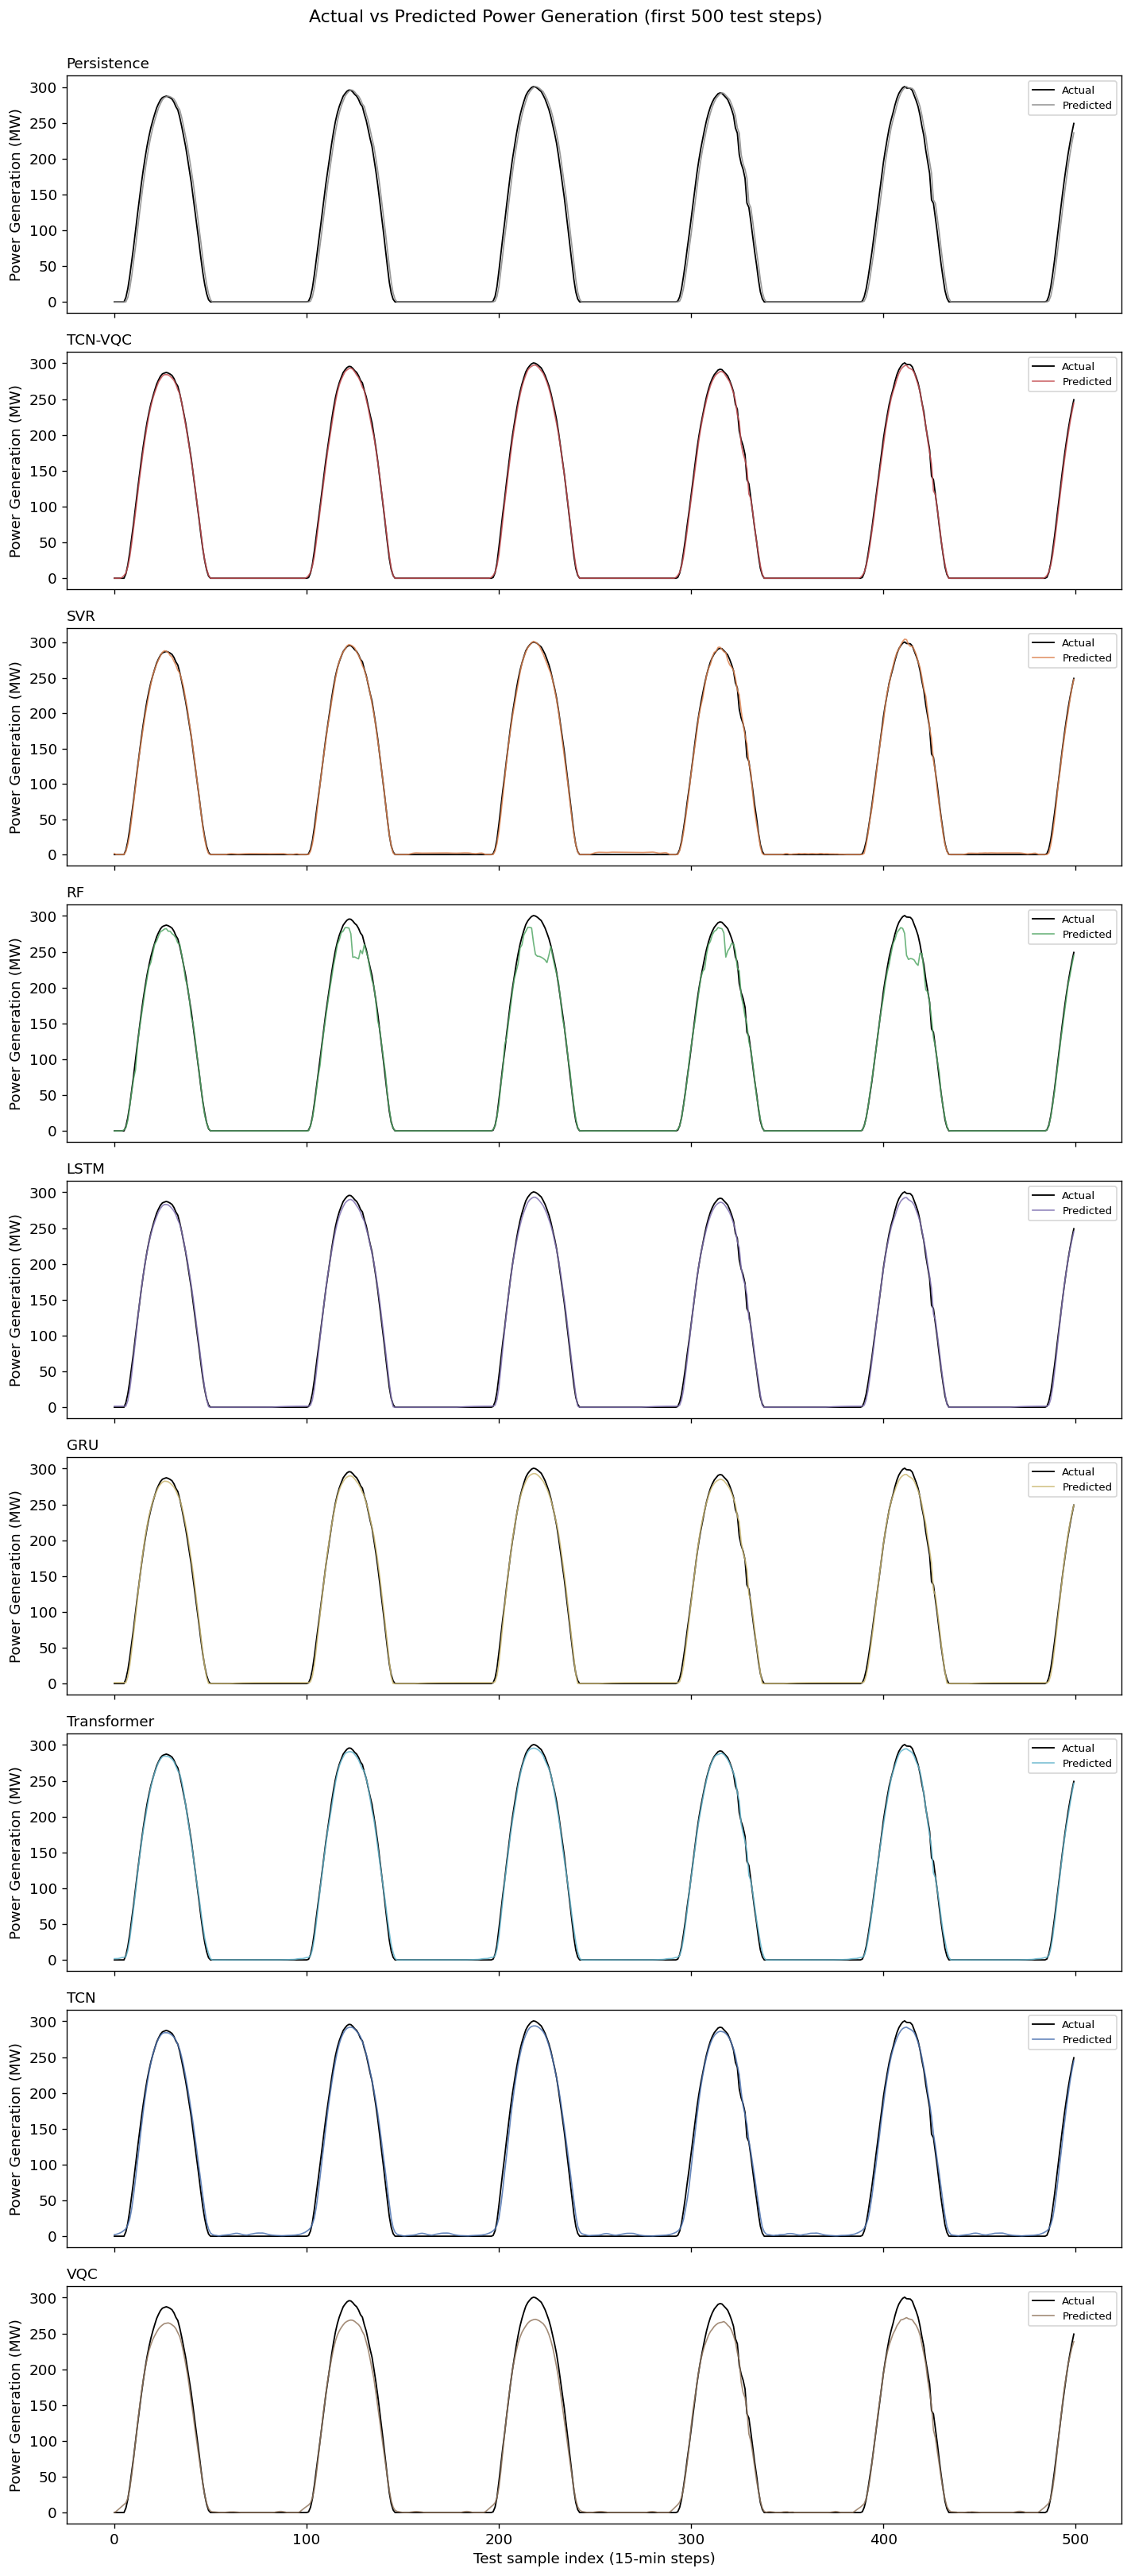

In [46]:
# --- Actual vs Predicted (zoomed to first N test points for readability) ---
n_points = 500
fig, axes = plt.subplots(len(RESULTS), 1, figsize=(12, 3 * len(RESULTS)), sharex=True)
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    ax.plot(y_true[:n_points], label="Actual", color="black", linewidth=1.1)
    ax.plot(y_pred[:n_points], label="Predicted", color=MODEL_COLORS[name], linewidth=1.0, alpha=0.85)
    ax.set_ylabel("Power Generation (MW)")
    ax.set_title(name, fontsize=11, loc="left")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel(f"Test sample index ({CFG.time_step_minutes}-min steps)")
fig.suptitle("Actual vs Predicted Power Generation (first {} test steps)".format(n_points), y=1.0)
fig.tight_layout()
_savefig(fig, "actual_vs_predicted")


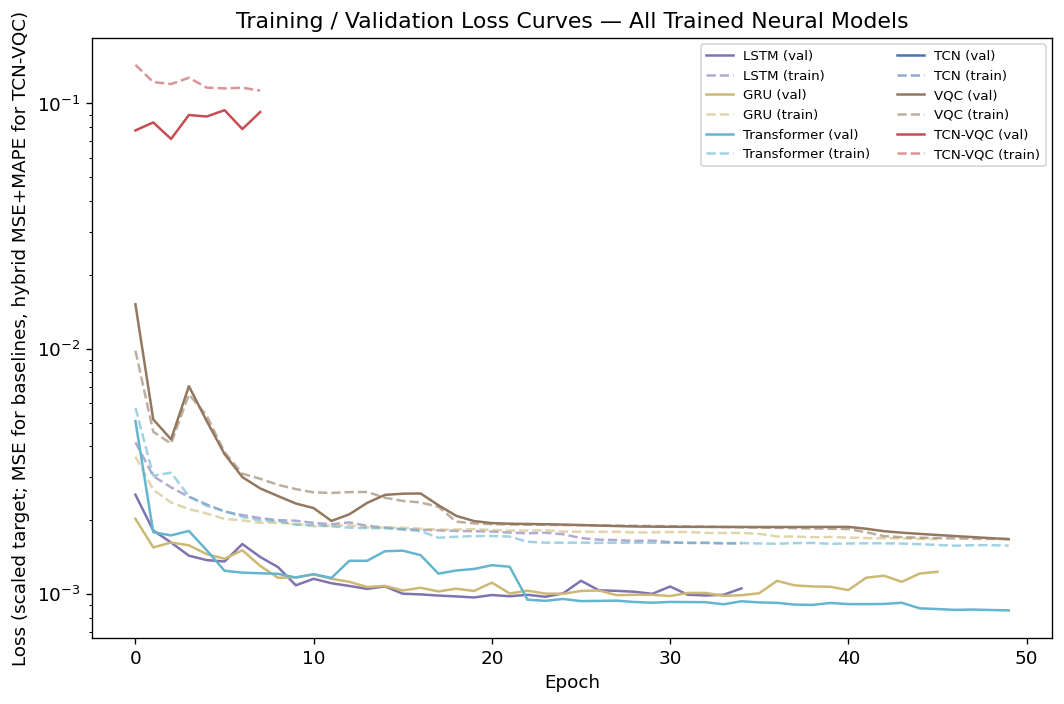

In [47]:
fig, ax = plt.subplots(figsize=(9, 6))
for name in TRAINED_NN_MODELS:
    hist = HISTORIES[name]["val_loss"]
    if hist:
        ax.plot(hist, label=f"{name} (val)", color=MODEL_COLORS[name])
    hist_tr = HISTORIES[name]["train_loss"]
    if hist_tr:
        ax.plot(hist_tr, label=f"{name} (train)", color=MODEL_COLORS[name], linestyle="--", alpha=0.6)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (scaled target; MSE for baselines, hybrid MSE+MAPE for TCN-VQC)")
ax.set_yscale("log")
ax.set_title("Training / Validation Loss Curves — All Trained Neural Models")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
_savefig(fig, "training_loss")


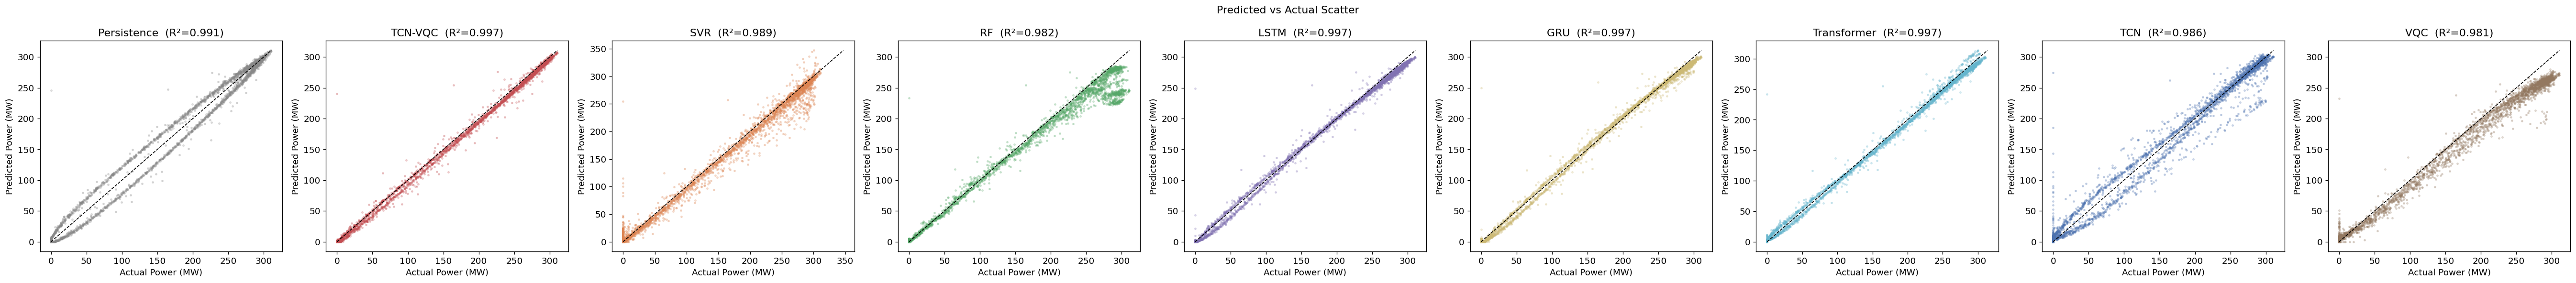

In [48]:
# --- Scatter: predicted vs actual ---
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 5))
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    ax.scatter(y_true, y_pred, s=4, alpha=0.25, color=MODEL_COLORS[name])
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(f"{name}  (R\u00b2={RESULTS[name]['R2']:.3f})")
    ax.set_xlabel("Actual Power (MW)")
    ax.set_ylabel("Predicted Power (MW)")
fig.suptitle("Predicted vs Actual Scatter")
fig.tight_layout()
_savefig(fig, "scatter")


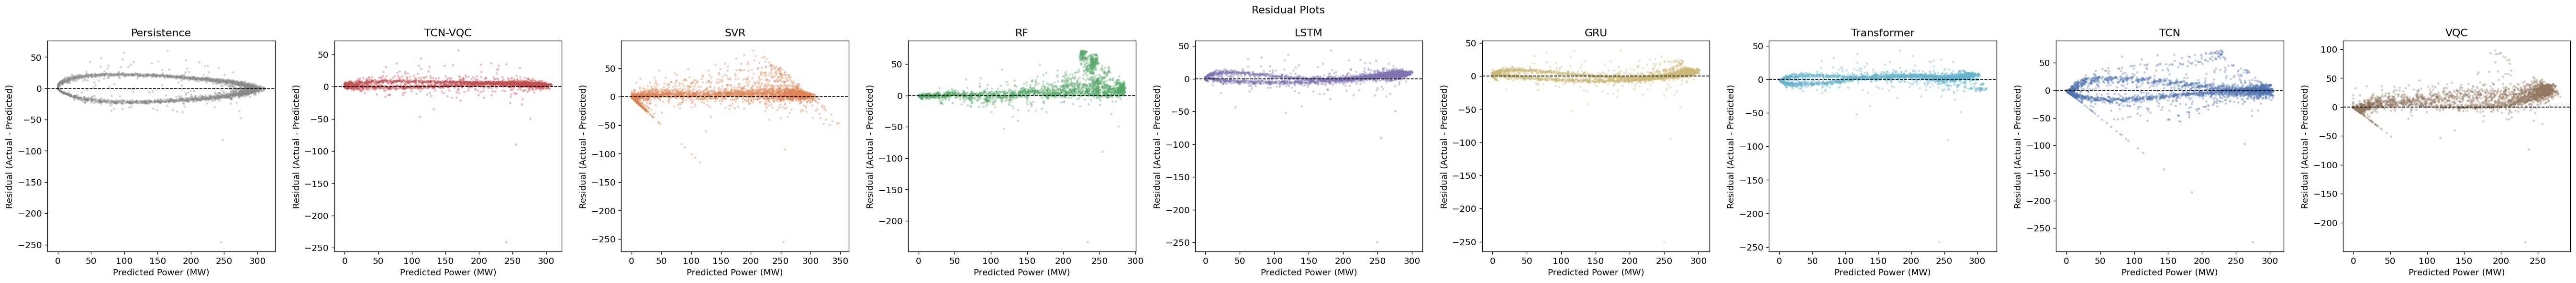

In [49]:
# --- Residual plots ---
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 5))
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    residuals = y_true - y_pred
    ax.scatter(y_pred, residuals, s=4, alpha=0.25, color=MODEL_COLORS[name])
    ax.axhline(0, color="black", linewidth=1, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted Power (MW)")
    ax.set_ylabel("Residual (Actual - Predicted)")
fig.suptitle("Residual Plots")
fig.tight_layout()
_savefig(fig, "residuals")


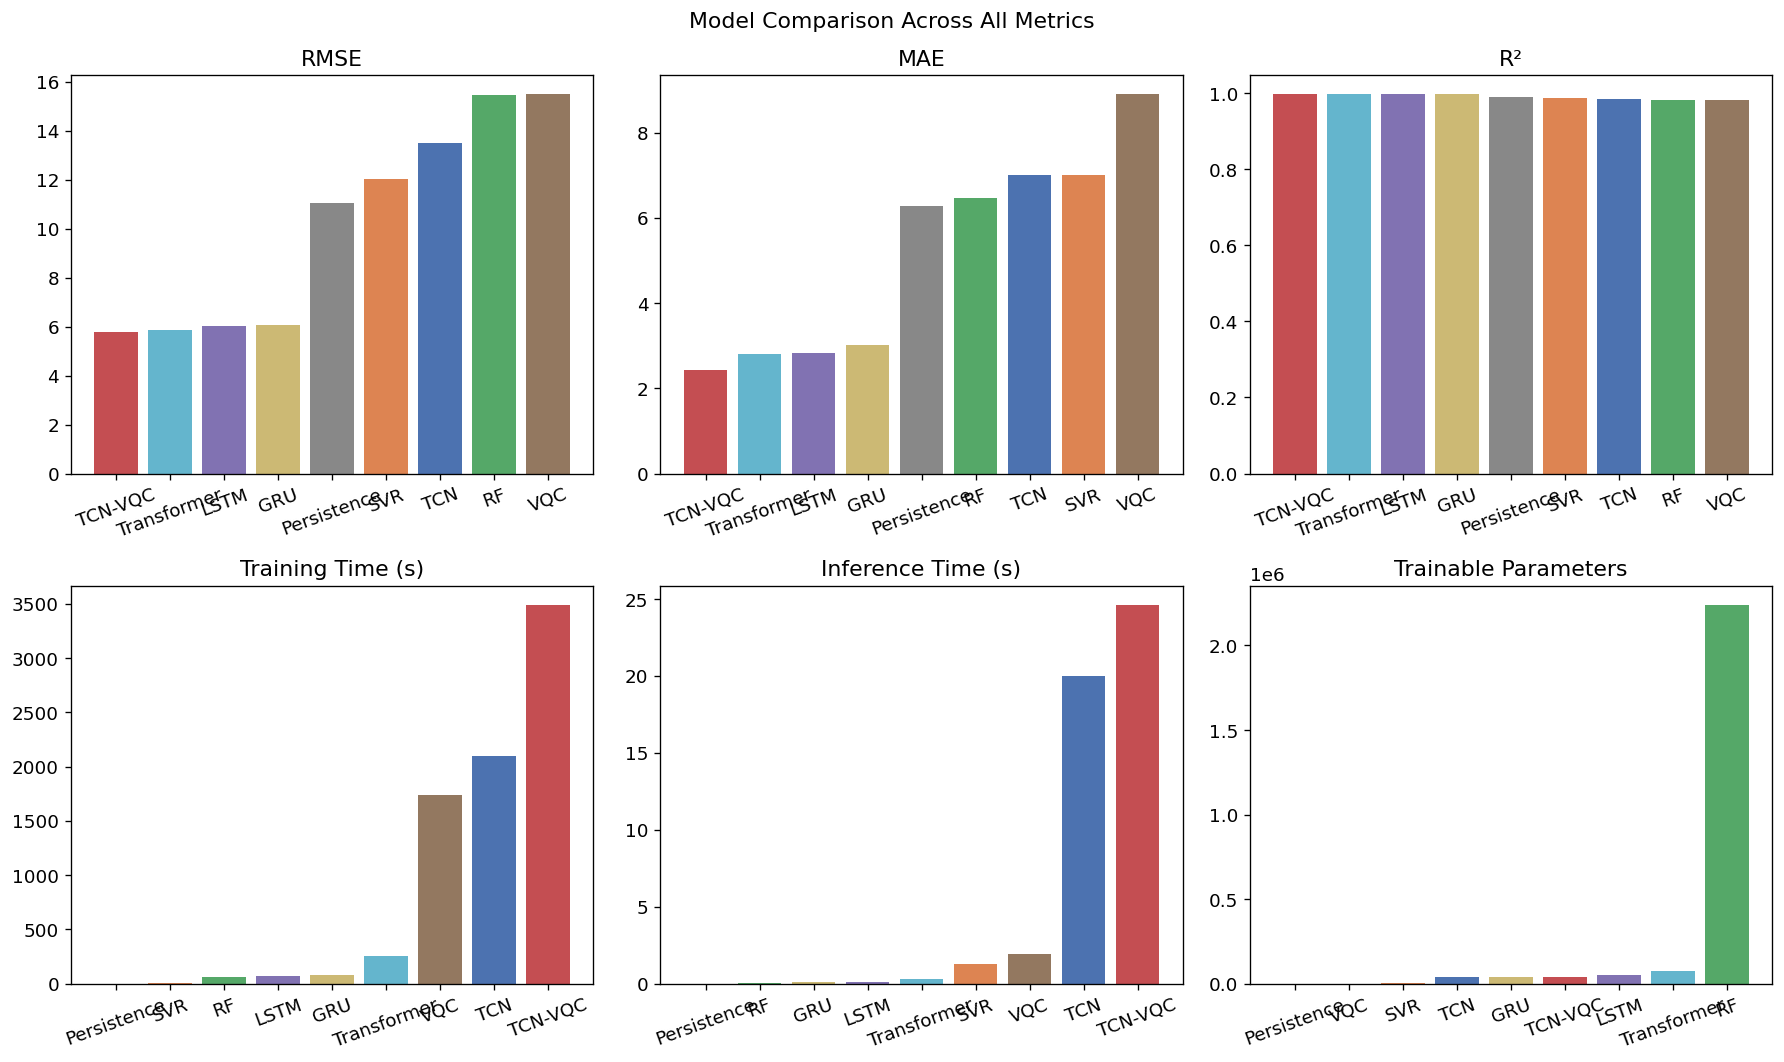

In [50]:
# --- Metric comparison bar charts (RMSE, MAE, R2, Training/Inference time) ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
metric_specs = [
    ("RMSE", "RMSE", True), ("MAE", "MAE", True), ("R2", "R\u00b2", False),
    ("Training_Time_s", "Training Time (s)", True), ("Inference_Time_s", "Inference Time (s)", True),
    ("Num_Params", "Trainable Parameters", True), ("MAPE" , "MAPE" , True)
]
for ax, (col, label, ascending) in zip(axes.ravel(), metric_specs):
    ordered = METRICS_DF.sort_values(col, ascending=ascending)
    colors = [MODEL_COLORS[m] for m in ordered["Model"]]
    ax.bar(ordered["Model"], ordered[col], color=colors)
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Model Comparison Across All Metrics")
fig.tight_layout()
_savefig(fig, "metric_comparison")


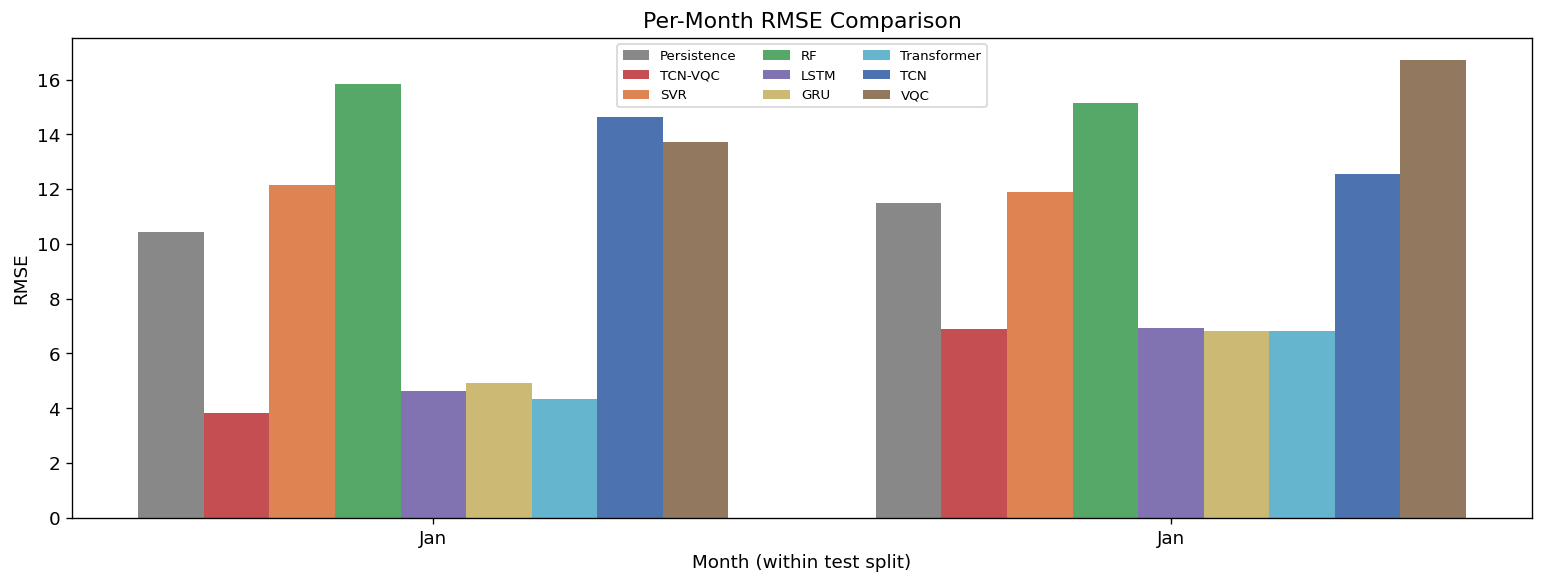

In [51]:
# --- Per-month RMSE comparison ---
fig, ax = plt.subplots(figsize=(13, 5))
n_models = len(RESULTS)
width = 0.8 / n_models  # NEW (comparison): scales automatically with however many models are in RESULTS
months_sorted = sorted(np.unique(DATA["test_months"]))
month_labels = [pd.Timestamp(2021, m, 1).strftime("%b") for m in months_sorted]
x = np.arange(len(months_sorted))
for i, name in enumerate(RESULTS.keys()):
    df_month = PER_MONTH_TABLES[name].set_index("Month").reindex(months_sorted)
    ax.bar(x + i * width, df_month["RMSE"], width=width, label=name, color=MODEL_COLORS[name])
ax.set_xticks(x + width * (n_models - 1) / 2)
ax.set_xticklabels(month_labels)
ax.set_xlabel("Month (within test split)")
ax.set_ylabel("RMSE")
ax.set_title("Per-Month RMSE Comparison")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
_savefig(fig, "per_month_rmse")


## 17. Explainability — Permutation Feature Importance

Model-agnostic sanity check: for the main TCN-VQC model, each input feature is shuffled
across the test set (breaking its relationship with the target while preserving its
marginal distribution) and the resulting RMSE degradation is measured. Larger degradation
= the model relies more on that feature. This works identically regardless of the quantum
head, since it only touches inputs/outputs, not internals.

,Feature,RMSE_increase,Std
0,Actual,149.8259,0.9461
1,TOD_sin,3.4940,0.0517
2,Available Capacity,2.6011,0.0416
3,TOD_cos,1.6213,0.0396
4,Radiation GII,0.1862,0.0143
5,Radiation GHI,0.0893,0.0218
6,Humidity Relative,0.0443,0.0015
7,Wind Speed,0.0265,0.0170
8,Wind Direction,0.0181,0.0009
9,Module Temperature,0.0000,0.0000


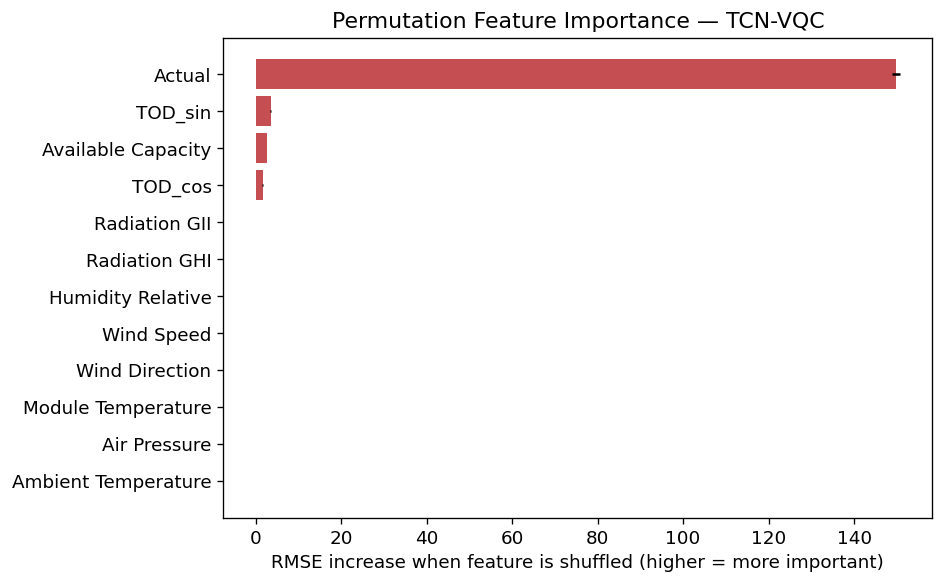

In [52]:
def permutation_importance(model: nn.Module, X_test: np.ndarray, y_test: np.ndarray,
                            target_scaler: MinMaxScaler, feature_names: list,
                            cfg: Config = CFG, n_repeats: int = 3) -> pd.DataFrame:
    model = model.to(cfg.device).eval()
    X_tensor_base = torch.from_numpy(X_test).float()

    def rmse_for(X_arr):
        preds = []
        with torch.no_grad():
            for i in range(0, len(X_arr), cfg.batch_size):
                xb = torch.from_numpy(X_arr[i:i + cfg.batch_size]).float().to(cfg.device)
                preds.append(model(xb).cpu().numpy())
        y_pred = inverse_scale(target_scaler, np.concatenate(preds).ravel())
        y_pred = np.clip(y_pred, 0.0, None)  # NEW (v3): power output is physically non-negative
        y_true = inverse_scale(target_scaler, y_test)
        return math.sqrt(mean_squared_error(y_true, y_pred))

    baseline_rmse = rmse_for(X_test)
    rng = np.random.default_rng(cfg.seed)
    importances = []
    for f_idx, f_name in enumerate(feature_names):
        degradations = []
        for _ in range(n_repeats):
            X_perm = X_test.copy()
            perm_order = rng.permutation(len(X_perm))
            X_perm[:, :, f_idx] = X_perm[perm_order, :, f_idx]
            degradations.append(rmse_for(X_perm) - baseline_rmse)
        importances.append({"Feature": f_name, "RMSE_increase": np.mean(degradations), "Std": np.std(degradations)})

    return pd.DataFrame(importances).sort_values("RMSE_increase", ascending=False).reset_index(drop=True)


IMPORTANCE_DF = permutation_importance(
    tcn_vqc_model, DATA["X_test"], DATA["y_test"], DATA["target_scaler"], DATA["feature_names"], CFG,
)
display(IMPORTANCE_DF.round(4))
IMPORTANCE_DF.to_csv(os.path.join(CFG.out_dir, "metrics", "permutation_importance_tcn_vqc.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ordered = IMPORTANCE_DF.sort_values("RMSE_increase")
ax.barh(ordered["Feature"], ordered["RMSE_increase"], xerr=ordered["Std"], color="#C44E52")
ax.set_xlabel("RMSE increase when feature is shuffled (higher = more important)")
ax.set_title("Permutation Feature Importance \u2014 TCN-VQC")
fig.tight_layout()
_savefig(fig, "permutation_importance")


In [53]:
from scipy import stats  # only used for the Q-Q plot (Infographic 19)


def get_test_timestamps(df: pd.DataFrame, cfg: Config = CFG) -> np.ndarray:
    n = len(df)
    train_end = int(n * cfg.train_frac)
    val_end = int(n * (cfg.train_frac + cfg.val_frac))
    seq_len, horizon = cfg.seq_len, cfg.horizon_steps
    ctx_lo = max(0, val_end - (seq_len + horizon - 1))

    dummy_feats = np.zeros((n - ctx_lo, 1), dtype=np.float32)
    ts_slice = df["__timestamp"].iloc[ctx_lo:n].reset_index(drop=True)
    _, _, kept_idx = create_sequences_gap_aware(
        dummy_feats, dummy_feats[:, 0], ts_slice, seq_len, horizon, cfg.time_step_minutes
    )
    target_positions = ctx_lo + kept_idx + seq_len + horizon - 1
    return df["__timestamp"].values[target_positions]


TEST_TIMESTAMPS = pd.to_datetime(get_test_timestamps(RAW_DF, CFG))
assert len(TEST_TIMESTAMPS) == len(DATA["y_test"]), "timestamp alignment mismatch — check prepare_data windowing logic"
TEST_HOURS = TEST_TIMESTAMPS.hour + TEST_TIMESTAMPS.minute / 60.0
print(f"Test timestamps aligned: {len(TEST_TIMESTAMPS)} samples "
      f"({TEST_TIMESTAMPS.min()} to {TEST_TIMESTAMPS.max()})")

Test timestamps aligned: 5256 samples (2022-02-05 06:00:00 to 2022-03-31 23:45:00)


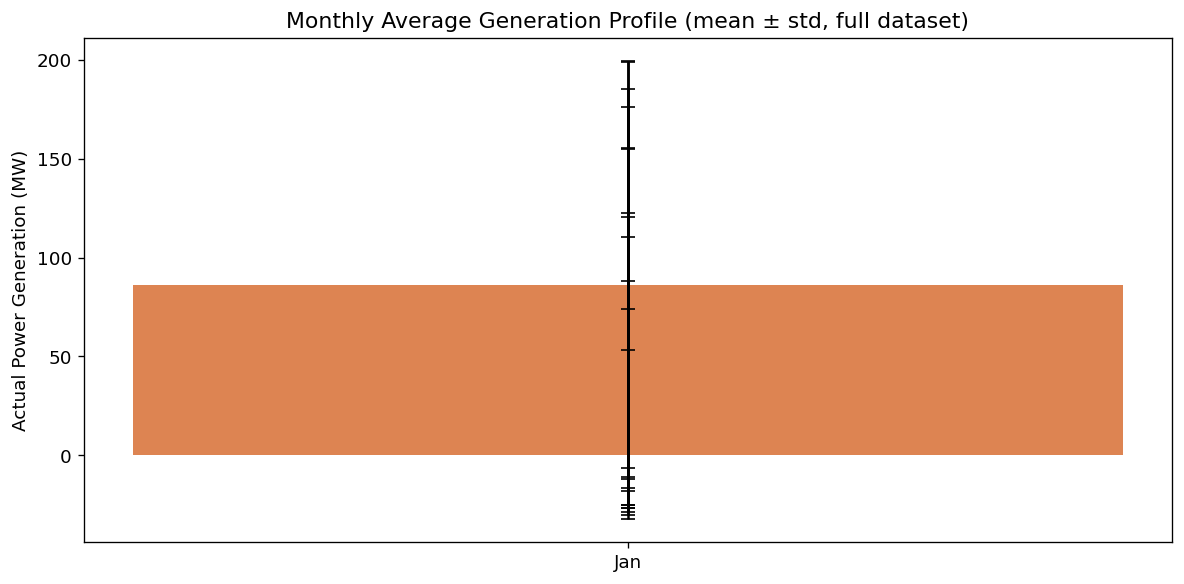

In [54]:
# --- Infographic 1: Monthly Average Generation Profile (full dataset) ---
monthly = RAW_DF.groupby("Month")["Actual"].agg(["mean", "std"])
month_labels_full = [pd.Timestamp(2021, m, 1).strftime("%b") for m in monthly.index]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(month_labels_full, monthly["mean"], yerr=monthly["std"], capsize=4, color="#DD8452")
ax.set_ylabel("Actual Power Generation (MW)")
ax.set_title("Monthly Average Generation Profile (mean ± std, full dataset)")
fig.tight_layout()
_savefig(fig, "info01_monthly_generation_profile")


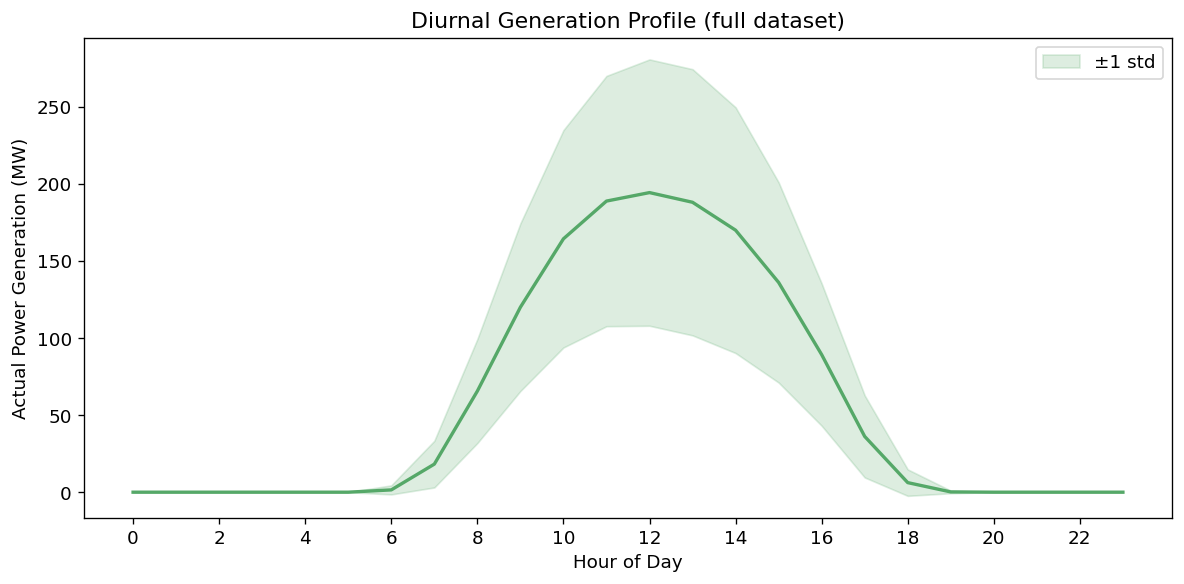

In [55]:
# --- Infographic 2: Diurnal (Hourly) Generation Profile ---
hourly = RAW_DF.assign(Hour=RAW_DF["__timestamp"].dt.hour).groupby("Hour")["Actual"].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hourly.index, hourly["mean"], color="#55A868", linewidth=2)
ax.fill_between(hourly.index, hourly["mean"] - hourly["std"], hourly["mean"] + hourly["std"],
                 color="#55A868", alpha=0.2, label="±1 std")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Actual Power Generation (MW)")
ax.set_title("Diurnal Generation Profile (full dataset)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
_savefig(fig, "info02_diurnal_profile")


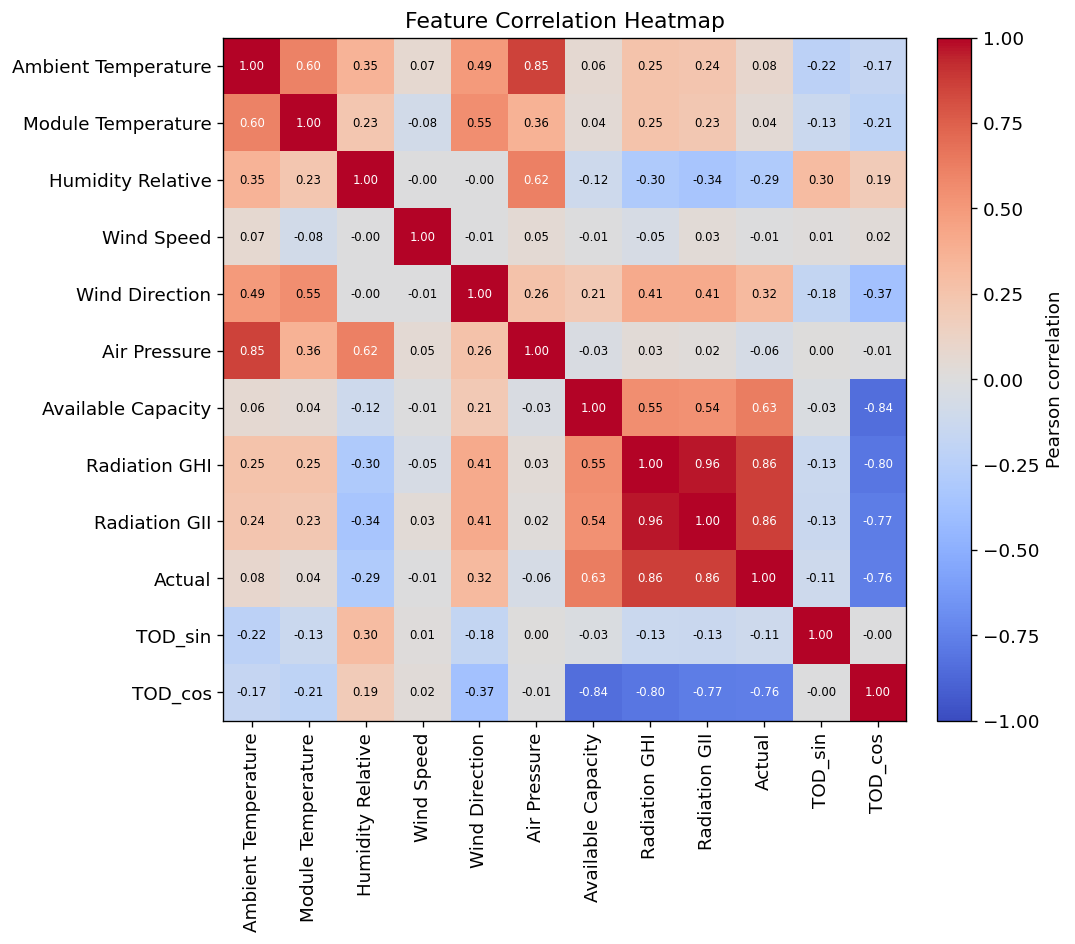

In [56]:
# --- Infographic 3: Feature Correlation Heatmap ---
corr_cols = list(CFG.feature_cols)
corr = RAW_DF[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                 color="white" if abs(corr.values[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Feature Correlation Heatmap")
fig.tight_layout()
_savefig(fig, "info03_correlation_heatmap")

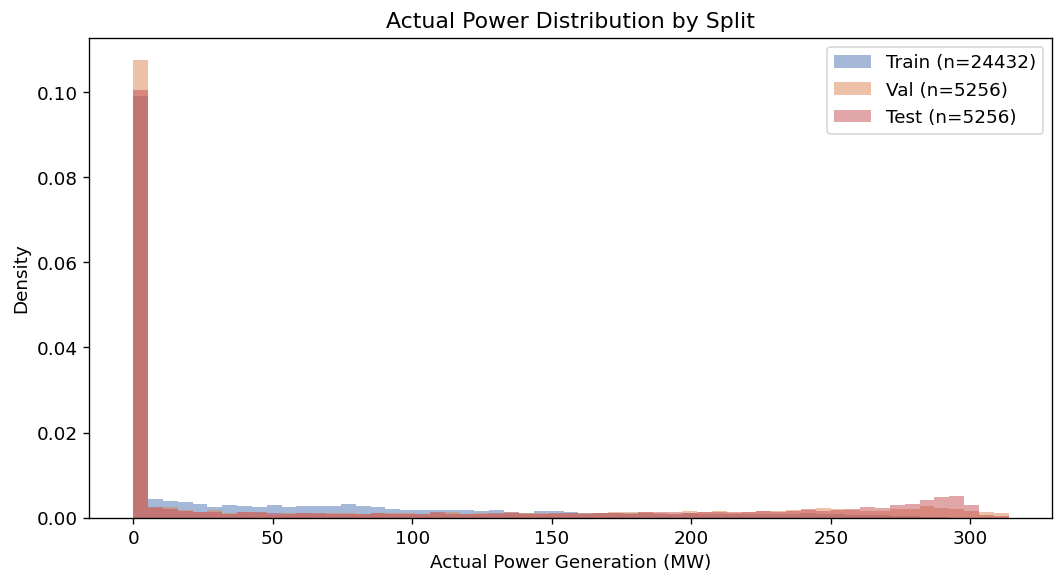

In [57]:
# --- Infographic 4: Actual Power Distribution by Split ---
y_train_mw = inverse_scale(DATA["target_scaler"], DATA["y_train"])
y_val_mw = inverse_scale(DATA["target_scaler"], DATA["y_val"])
y_test_mw = inverse_scale(DATA["target_scaler"], DATA["y_test"])
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(0, max(y_train_mw.max(), y_val_mw.max(), y_test_mw.max()), 60)
for arr, label, color in [(y_train_mw, "Train", "#4C72B0"), (y_val_mw, "Val", "#DD8452"),
                            (y_test_mw, "Test", "#C44E52")]:
    ax.hist(arr, bins=bins, alpha=0.5, label=f"{label} (n={len(arr)})", color=color, density=True)
ax.set_xlabel("Actual Power Generation (MW)")
ax.set_ylabel("Density")
ax.set_title("Actual Power Distribution by Split")
ax.legend()
fig.tight_layout()
_savefig(fig, "info04_actual_distribution_by_split")

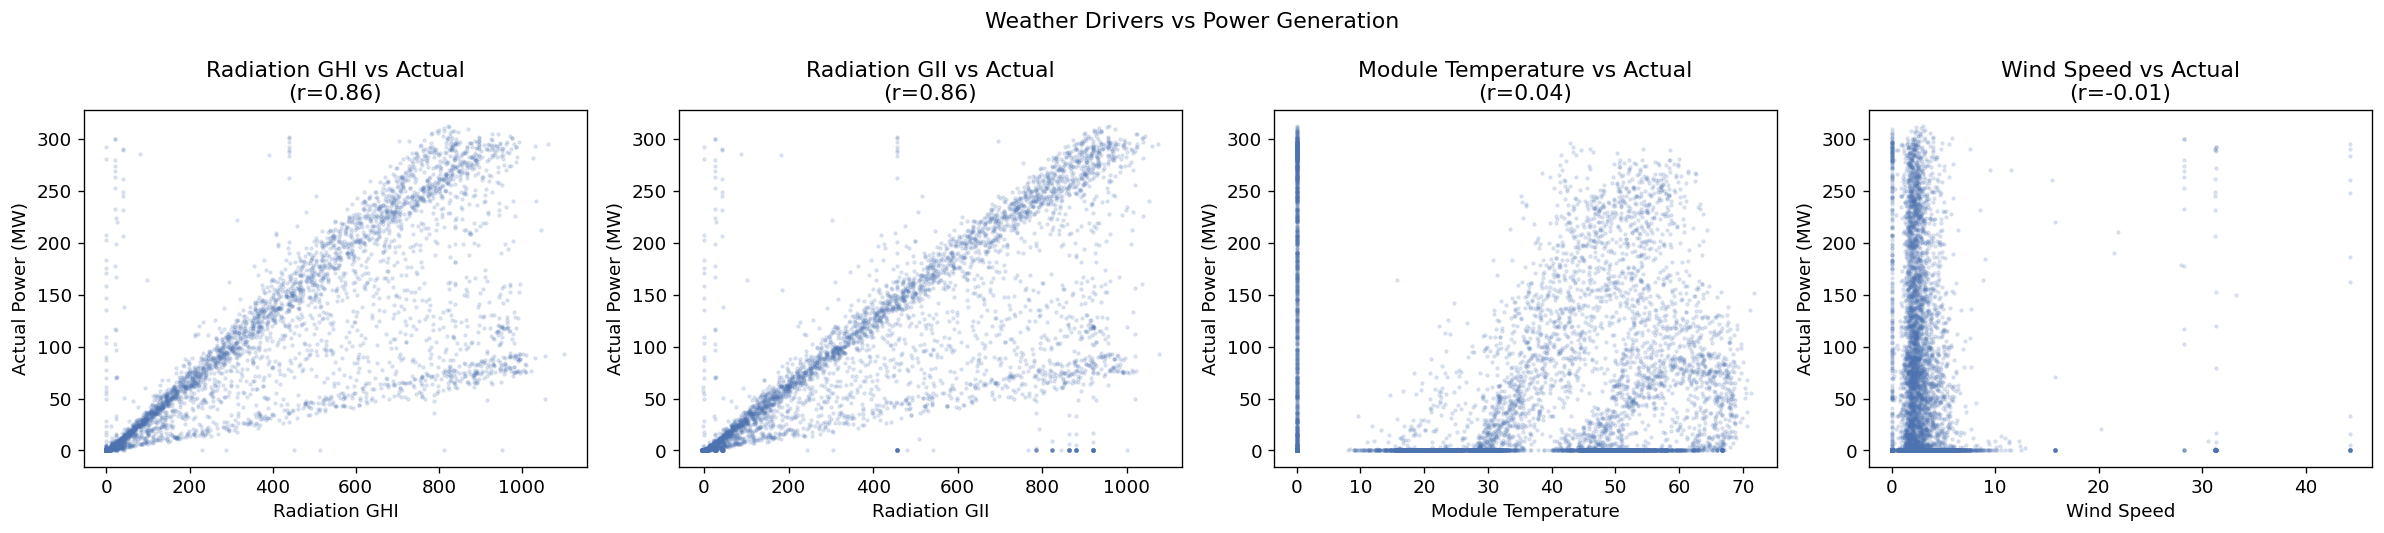

In [58]:
# --- Infographic 5: Weather Driver Scatter Grid ---
drivers = ["Radiation GHI", "Radiation GII", "Module Temperature", "Wind Speed"]
fig, axes = plt.subplots(1, len(drivers), figsize=(5 * len(drivers), 4.5))
sample = RAW_DF.sample(min(8000, len(RAW_DF)), random_state=CFG.seed)
for ax, col in zip(axes, drivers):
    ax.scatter(sample[col], sample["Actual"], s=3, alpha=0.15, color="#4C72B0")
    ax.set_xlabel(col)
    ax.set_ylabel("Actual Power (MW)")
    ax.set_title(f"{col} vs Actual\n(r={RAW_DF[col].corr(RAW_DF['Actual']):.2f})")
fig.suptitle("Weather Drivers vs Power Generation")
fig.tight_layout()
_savefig(fig, "info05_weather_driver_scatter")

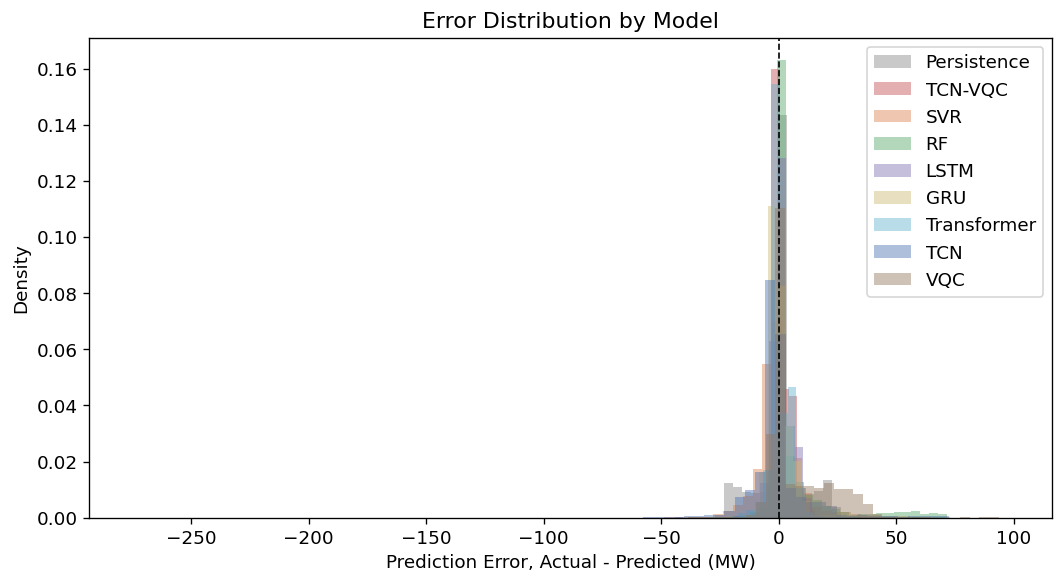

In [59]:
# --- Infographic 6: Prediction Error Distribution (all models overlaid) ---
fig, ax = plt.subplots(figsize=(9, 5))
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    err = y_true - y_pred
    ax.hist(err, bins=80, alpha=0.45, label=name, color=MODEL_COLORS[name], density=True)
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("Prediction Error, Actual - Predicted (MW)")
ax.set_ylabel("Density")
ax.set_title("Error Distribution by Model")
ax.legend()
fig.tight_layout()
_savefig(fig, "info06_error_distribution")

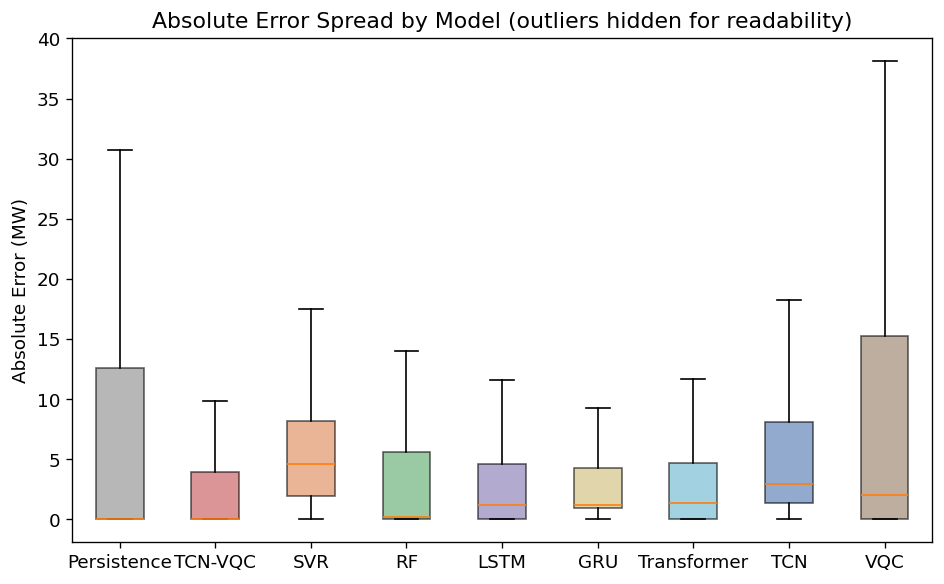

In [60]:
# --- Infographic 7: Absolute Error Boxplot by Model ---
fig, ax = plt.subplots(figsize=(8, 5))
data_box = [np.abs(PREDICTIONS[name][0] - PREDICTIONS[name][1]) for name in RESULTS.keys()]
bp = ax.boxplot(data_box, labels=list(RESULTS.keys()), patch_artist=True, showfliers=False)
for patch, name in zip(bp["boxes"], RESULTS.keys()):
    patch.set_facecolor(MODEL_COLORS[name])
    patch.set_alpha(0.6)
ax.set_ylabel("Absolute Error (MW)")
ax.set_title("Absolute Error Spread by Model (outliers hidden for readability)")
fig.tight_layout()
_savefig(fig, "info07_abs_error_boxplot")

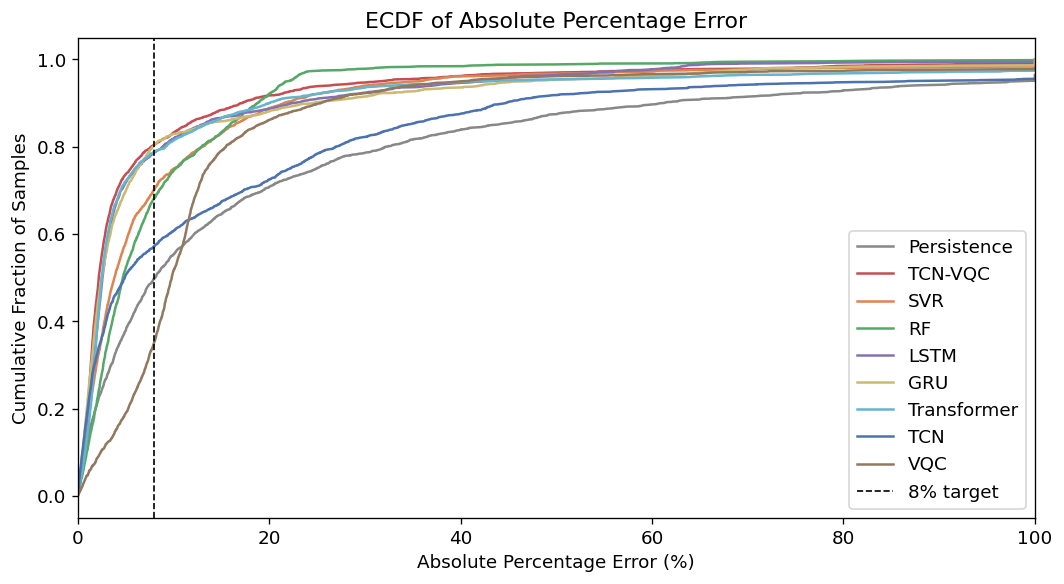

In [ ]:
# --- Infographic 8: Empirical CDF of Absolute Percentage Error ---
fig, ax = plt.subplots(figsize=(9, 5))
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    mask = y_true > CFG.mape_eps_mw
    ape = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]) * 100
    sorted_ape = np.sort(ape)
    cdf = np.arange(1, len(sorted_ape) + 1) / len(sorted_ape)
    ax.plot(sorted_ape, cdf, label=name, color=MODEL_COLORS[name])

ax.set_xlim(0, 100)
ax.set_xlabel("Absolute Percentage Error (%)")
ax.set_ylabel("Cumulative Fraction of Samples")
ax.set_title("ECDF of Absolute Percentage Error")
ax.legend()
fig.tight_layout()
_savefig(fig, "info08_ape_ecdf")

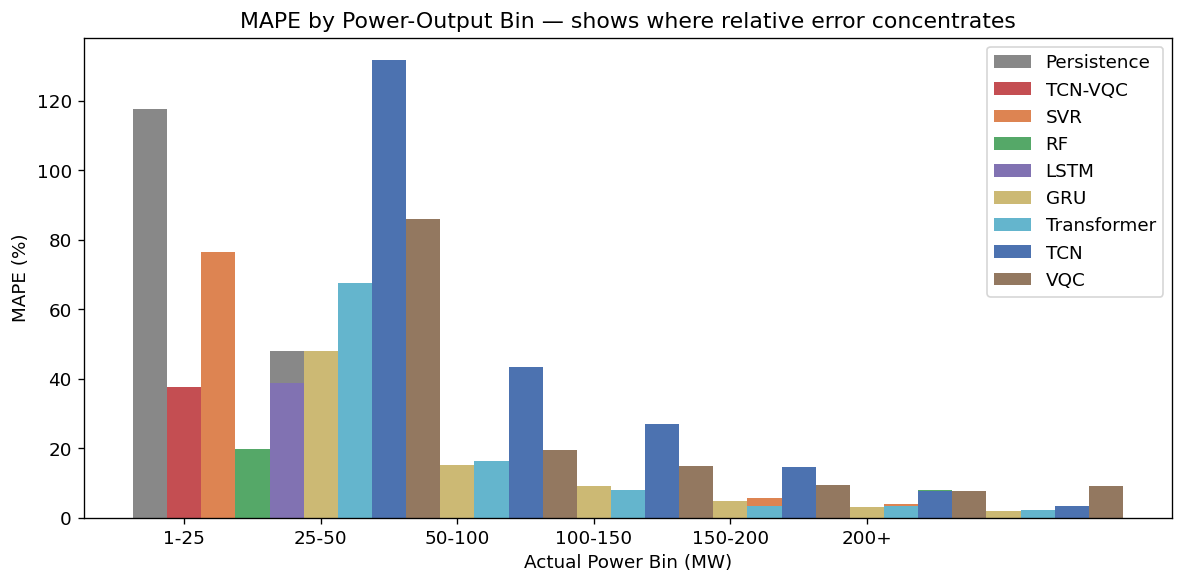

In [62]:
# --- Infographic 9: MAPE by Power-Output Bin ---
cap = max(PREDICTIONS[name][0].max() for name in RESULTS) + 1
bins = [1, 25, 50, 100, 150, 200, cap]
bin_labels = ["1-25", "25-50", "50-100", "100-150", "150-200", "200+"]
fig, ax = plt.subplots(figsize=(10, 5))
width = 0.25
x = np.arange(len(bin_labels))
for i, name in enumerate(RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    mape_per_bin = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_true >= lo) & (y_true < hi)
        if mask.sum() == 0:
            mape_per_bin.append(np.nan)
            continue
        mape_per_bin.append(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)
    ax.bar(x + i * width, mape_per_bin, width=width, label=name, color=MODEL_COLORS[name])
ax.set_xticks(x + width)
ax.set_xticklabels(bin_labels)
ax.set_xlabel("Actual Power Bin (MW)")
ax.set_ylabel("MAPE (%)")
ax.set_title("MAPE by Power-Output Bin — shows where relative error concentrates")
ax.legend()
fig.tight_layout()
_savefig(fig, "info09_mape_by_power_bin")

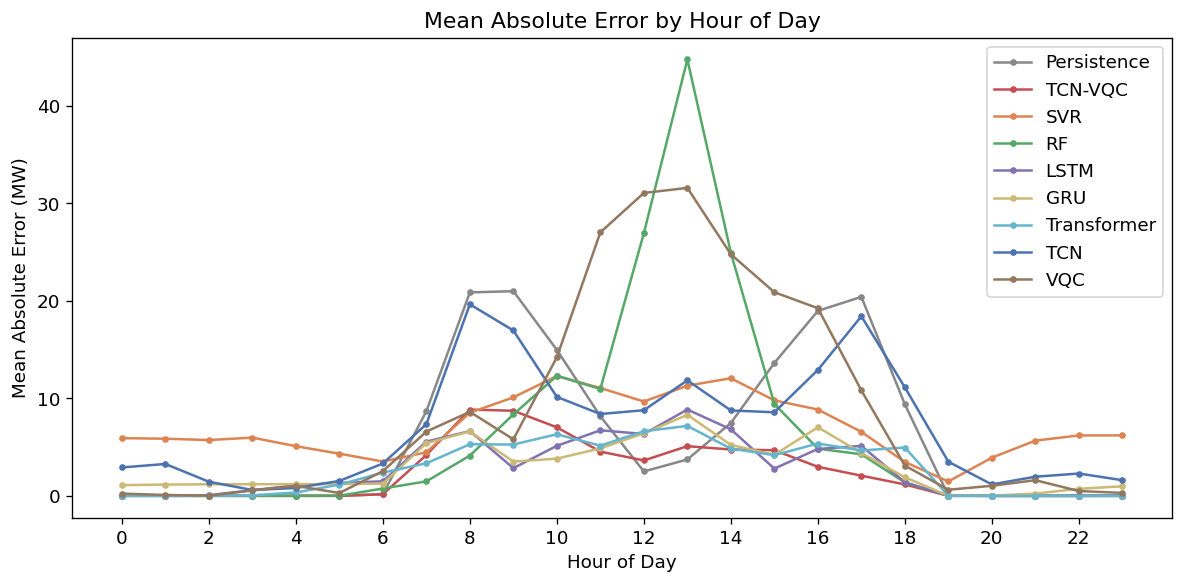

In [63]:
# --- Infographic 10: Mean Absolute Error by Hour of Day ---
fig, ax = plt.subplots(figsize=(10, 5))
hour_bins = np.arange(0, 25, 1)
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    abs_err = np.abs(y_true - y_pred)
    df_h = pd.DataFrame({"hour": TEST_HOURS.values, "abs_err": abs_err})
    grouped = df_h.groupby(pd.cut(df_h["hour"], hour_bins, right=False))["abs_err"].mean()
    ax.plot(hour_bins[:-1], grouped.values, marker="o", markersize=3, label=name, color=MODEL_COLORS[name])
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean Absolute Error (MW)")
ax.set_title("Mean Absolute Error by Hour of Day")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
_savefig(fig, "info10_error_by_hour")

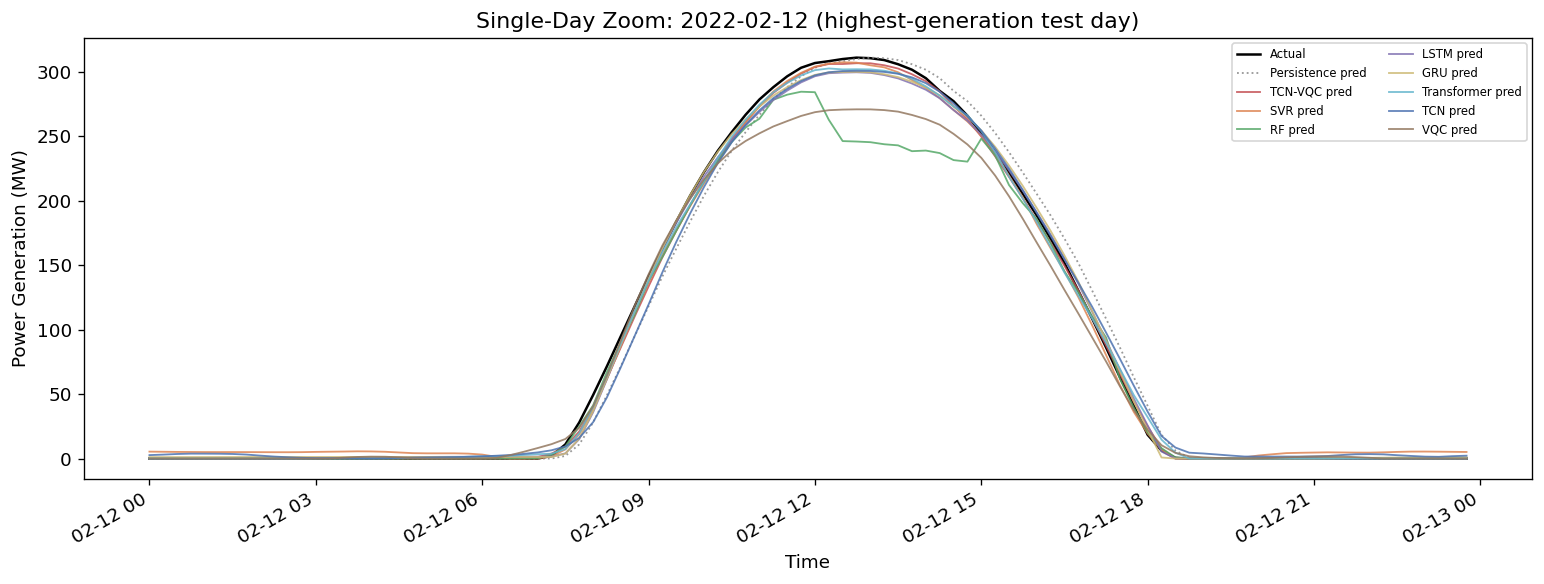

In [64]:
# --- Infographic 11: Single-Day Zoom (highest-generation test day) ---
test_dates = pd.Series(TEST_TIMESTAMPS).dt.date
peak_day = pd.Series(PREDICTIONS["TCN-VQC"][0], index=test_dates).groupby(level=0).max().idxmax()
day_mask = test_dates == peak_day
fig, ax = plt.subplots(figsize=(13, 5))
times_day = TEST_TIMESTAMPS[day_mask.values]
ax.plot(times_day, PREDICTIONS["Persistence"][0][day_mask.values], color="black", linewidth=1.5, label="Actual")
for name in RESULTS.keys():
    y_pred_day = PREDICTIONS[name][1][day_mask.values]
    style = dict(color=MODEL_COLORS[name], linewidth=1.1, alpha=0.85)
    if name == "Persistence":
        ax.plot(times_day, y_pred_day, linestyle=":", label=f"{name} pred", **style)
    else:
        ax.plot(times_day, y_pred_day, label=f"{name} pred", **style)
ax.set_xlabel("Time")
ax.set_ylabel("Power Generation (MW)")
ax.set_title(f"Single-Day Zoom: {peak_day} (highest-generation test day)")
ax.legend(fontsize=7, ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
_savefig(fig, "info11_single_day_zoom")


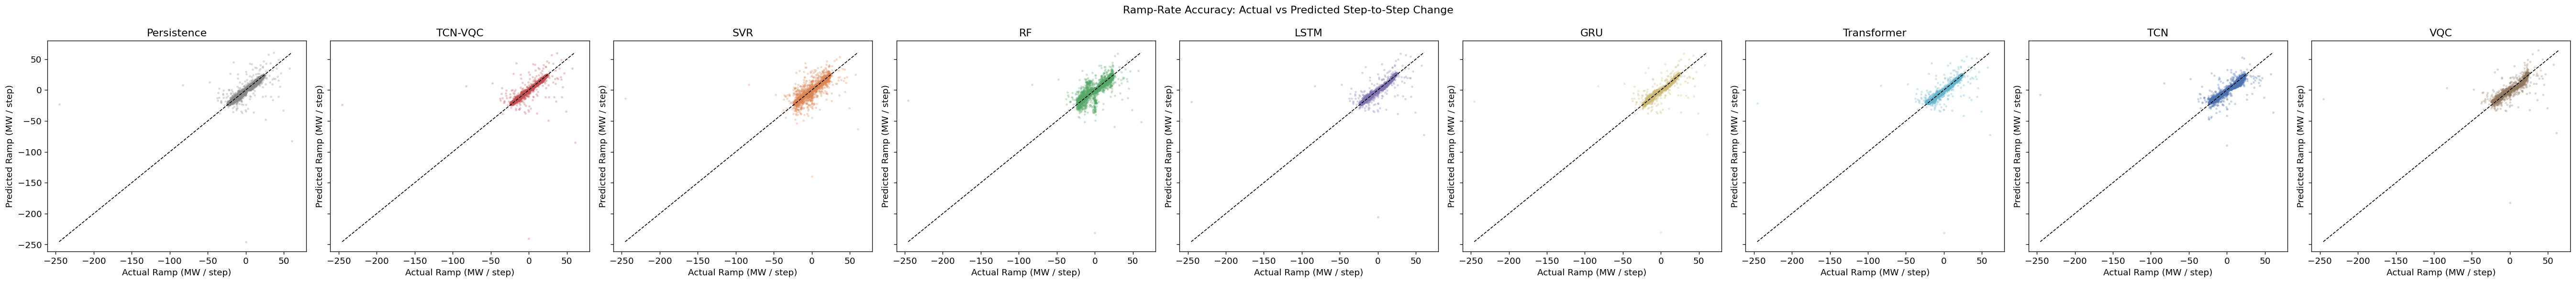

In [65]:
# --- Infographic 12: Ramp-Rate (step-to-step change) Actual vs Predicted ---
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 5), sharex=True, sharey=True)
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    ramp_true = np.diff(y_true)
    ramp_pred = np.diff(y_pred)
    ax.scatter(ramp_true, ramp_pred, s=4, alpha=0.2, color=MODEL_COLORS[name])
    lims = [min(ramp_true.min(), ramp_pred.min()), max(ramp_true.max(), ramp_pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual Ramp (MW / step)")
    ax.set_ylabel("Predicted Ramp (MW / step)")
fig.suptitle("Ramp-Rate Accuracy: Actual vs Predicted Step-to-Step Change")
fig.tight_layout()
_savefig(fig, "info12_ramp_rate_scatter")

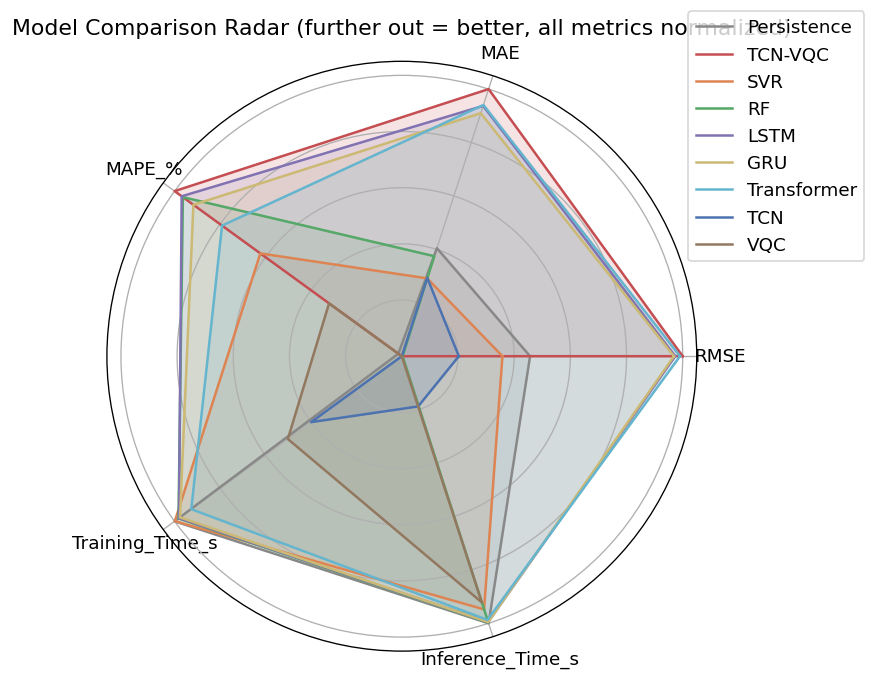

In [66]:
# --- Infographic 13: Radar Chart — Normalized Metric Comparison ---
radar_metrics = ["RMSE", "MAE", "MAPE_%", "Training_Time_s", "Inference_Time_s"]
# lower is better for all of these -> invert so "further out" always means "better" on the radar
norm_df = METRICS_DF.set_index("Model")[radar_metrics].copy()
norm_scores = 1 - (norm_df - norm_df.min()) / (norm_df.max() - norm_df.min() + 1e-9)
angles = np.linspace(0, 2 * np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
for name in RESULTS.keys():
    values = norm_scores.loc[name].tolist()
    values += values[:1]
    ax.plot(angles, values, label=name, color=MODEL_COLORS[name])
    ax.fill(angles, values, color=MODEL_COLORS[name], alpha=0.15)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics)
ax.set_yticklabels([])
ax.set_title("Model Comparison Radar (further out = better, all metrics normalized)")
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
fig.tight_layout()
_savefig(fig, "info13_radar_chart")


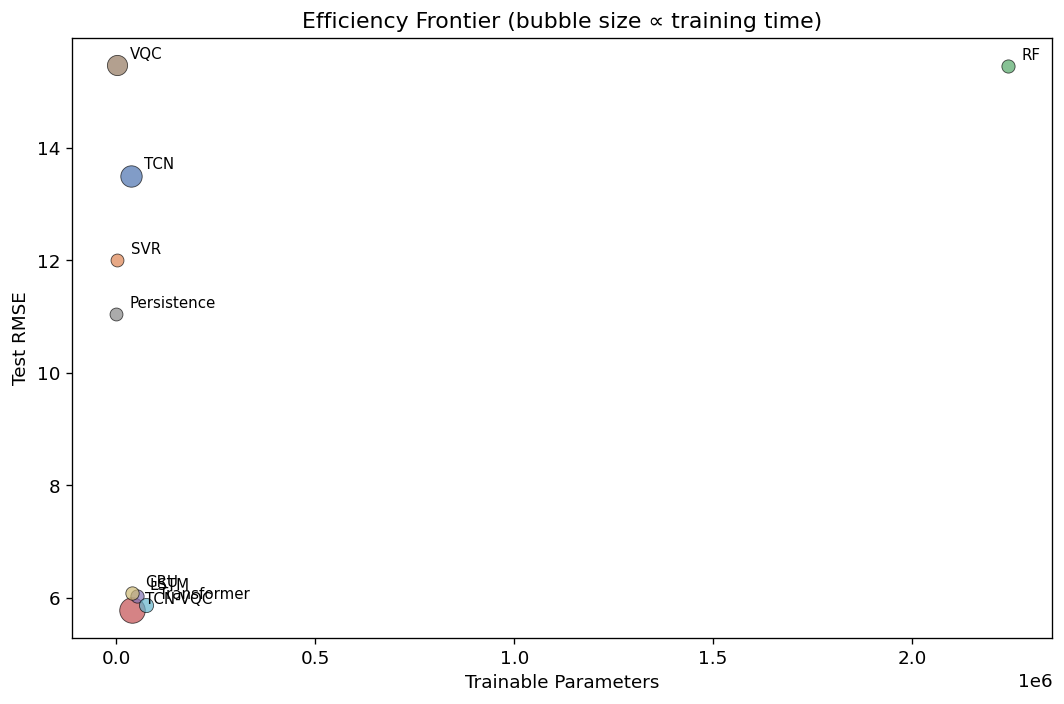

In [67]:
# --- Infographic 14: Efficiency Frontier — Params vs RMSE (bubble = training time) ---
fig, ax = plt.subplots(figsize=(9, 6))
for _, row in METRICS_DF.iterrows():
    size = max(row["Training_Time_s"], 1) * 0.05 + 60
    ax.scatter(row["Num_Params"], row["RMSE"], s=size, color=MODEL_COLORS[row["Model"]], alpha=0.7,
               edgecolor="black", linewidth=0.5)
    ax.annotate(row["Model"], (row["Num_Params"], row["RMSE"]),
                textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_xlabel("Trainable Parameters")
ax.set_ylabel("Test RMSE")
ax.set_title("Efficiency Frontier (bubble size ∝ training time)")
fig.tight_layout()
_savefig(fig, "info14_efficiency_frontier")


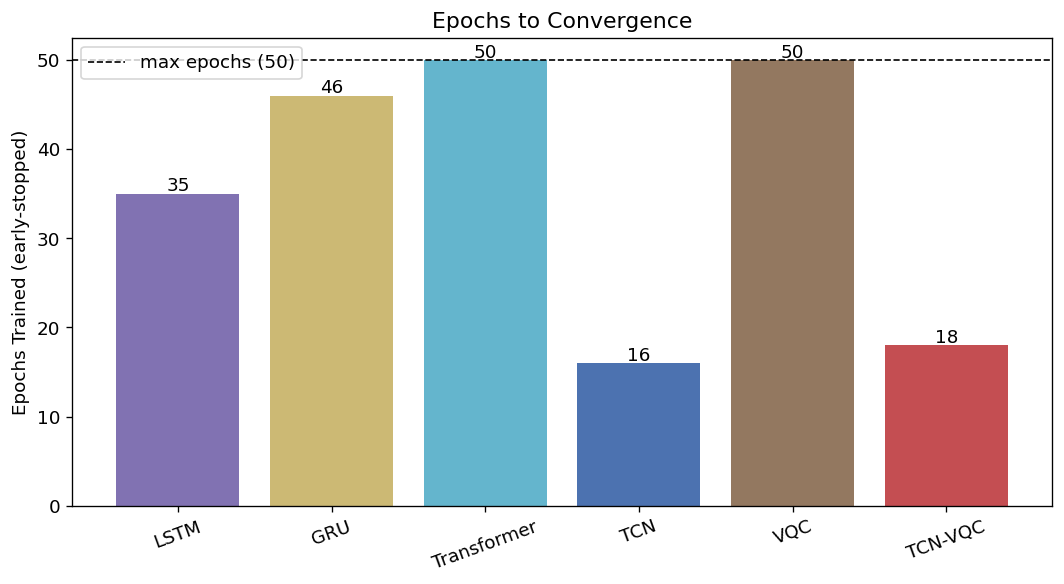

In [68]:
# --- Infographic 15: Epochs to Convergence (early stopping comparison) ---
fig, ax = plt.subplots(figsize=(9, 5))
epoch_counts = {name: len(HISTORIES[name]["train_loss"]) for name in TRAINED_NN_MODELS}
ax.bar(epoch_counts.keys(), epoch_counts.values(),
       color=[MODEL_COLORS[n] for n in epoch_counts.keys()])
for i, (name, cnt) in enumerate(epoch_counts.items()):
    ax.text(i, cnt + 0.3, str(cnt), ha="center")
ax.axhline(CFG.epochs, color="black", linestyle="--", linewidth=1, label=f"max epochs ({CFG.epochs})")
ax.set_ylabel("Epochs Trained (early-stopped)")
ax.set_title("Epochs to Convergence")
ax.tick_params(axis="x", rotation=20)
ax.legend()
fig.tight_layout()
_savefig(fig, "info15_epochs_to_convergence")


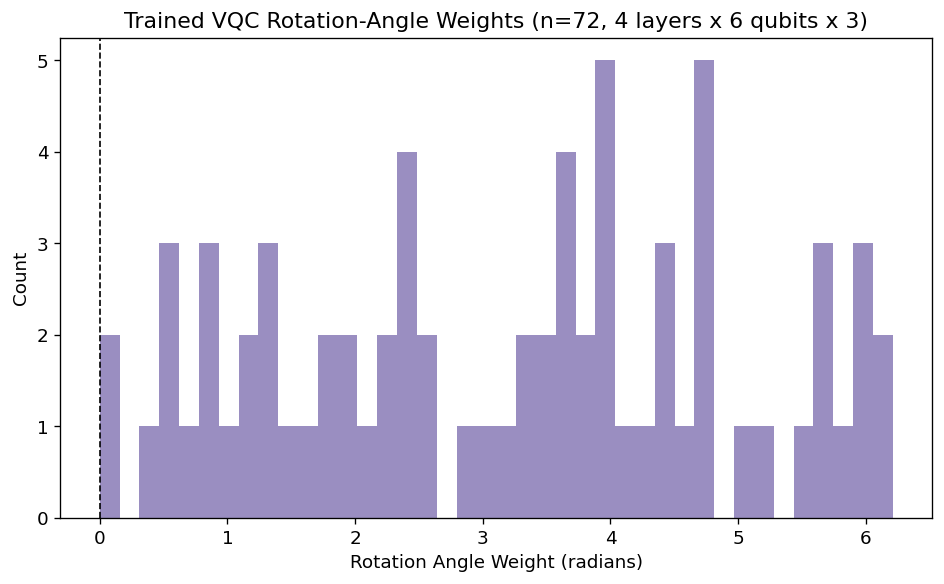

In [69]:
# --- Infographic 16: Trained VQC Weight Distribution ---
vqc_weights = tcn_vqc_model.qlayer.weights.detach().cpu().numpy().ravel()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(vqc_weights, bins=40, color="#8172B2", alpha=0.8)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Rotation Angle Weight (radians)")
ax.set_ylabel("Count")
ax.set_title(f"Trained VQC Rotation-Angle Weights (n={len(vqc_weights)}, "
             f"{Q_LAYERS} layers x {N_QUBITS} qubits x 3)")
fig.tight_layout()
_savefig(fig, "info16_vqc_weight_distribution")

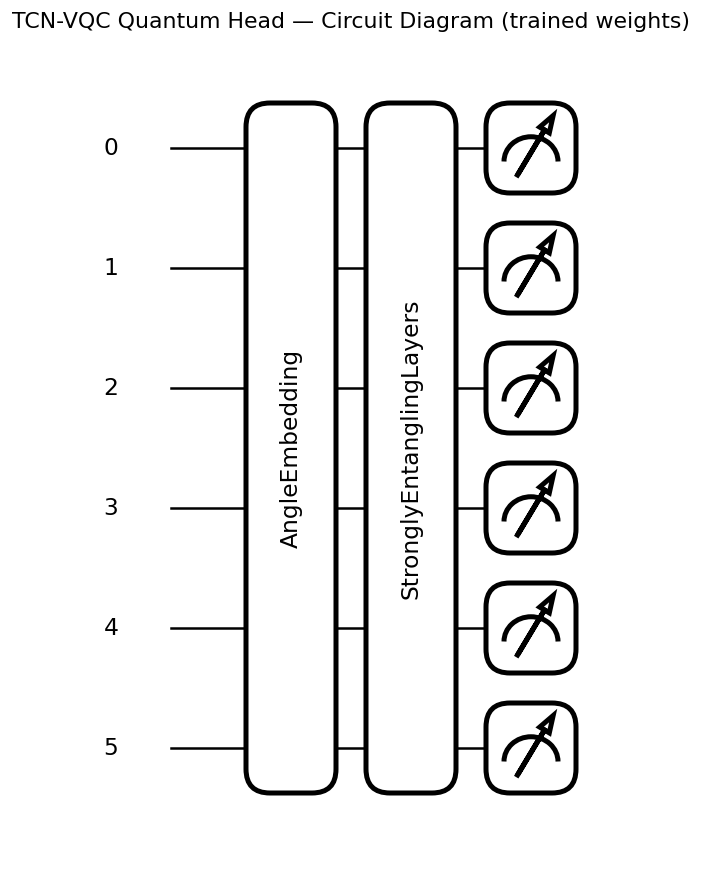

In [70]:
# --- Infographic 17: Quantum Circuit Diagram ---
_dummy_dev = qml.device("default.qubit", wires=N_QUBITS)


@qml.qnode(_dummy_dev)
def _circuit_for_drawing(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


_dummy_inputs = np.zeros(N_QUBITS)
_dummy_weights = tcn_vqc_model.qlayer.weights.detach().cpu().numpy()
fig, _ax = qml.draw_mpl(_circuit_for_drawing)(_dummy_inputs, _dummy_weights)
fig.suptitle("TCN-VQC Quantum Head — Circuit Diagram (trained weights)", y=1.02)
_savefig(fig, "info17_quantum_circuit_diagram")


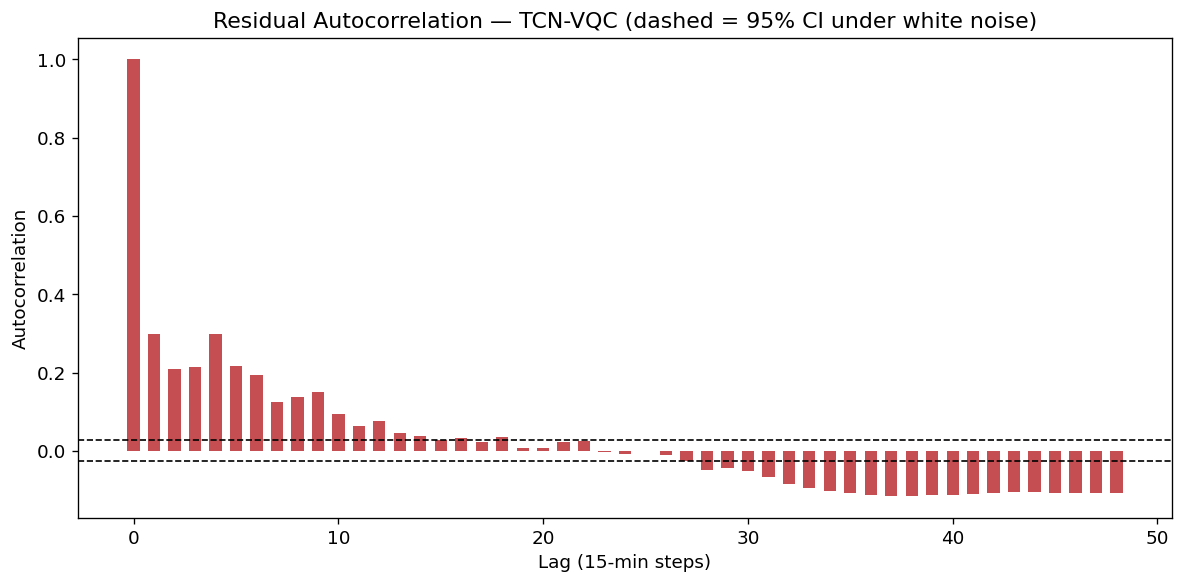

In [71]:
# --- Infographic 18: Autocorrelation of Residuals (TCN-VQC) ---
y_true, y_pred = PREDICTIONS["TCN-VQC"]
resid = y_true - y_pred
resid_centered = resid - resid.mean()
n_lags = 48  # 12 hours at 15-min resolution
acf = [1.0] + [
    np.corrcoef(resid_centered[:-lag], resid_centered[lag:])[0, 1] for lag in range(1, n_lags + 1)
]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(n_lags + 1), acf, color="#C44E52", width=0.6)
ci = 1.96 / np.sqrt(len(resid))
ax.axhline(ci, color="black", linestyle="--", linewidth=1)
ax.axhline(-ci, color="black", linestyle="--", linewidth=1)
ax.set_xlabel(f"Lag ({CFG.time_step_minutes}-min steps)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Residual Autocorrelation — TCN-VQC (dashed = 95% CI under white noise)")
fig.tight_layout()
_savefig(fig, "info18_residual_acf")

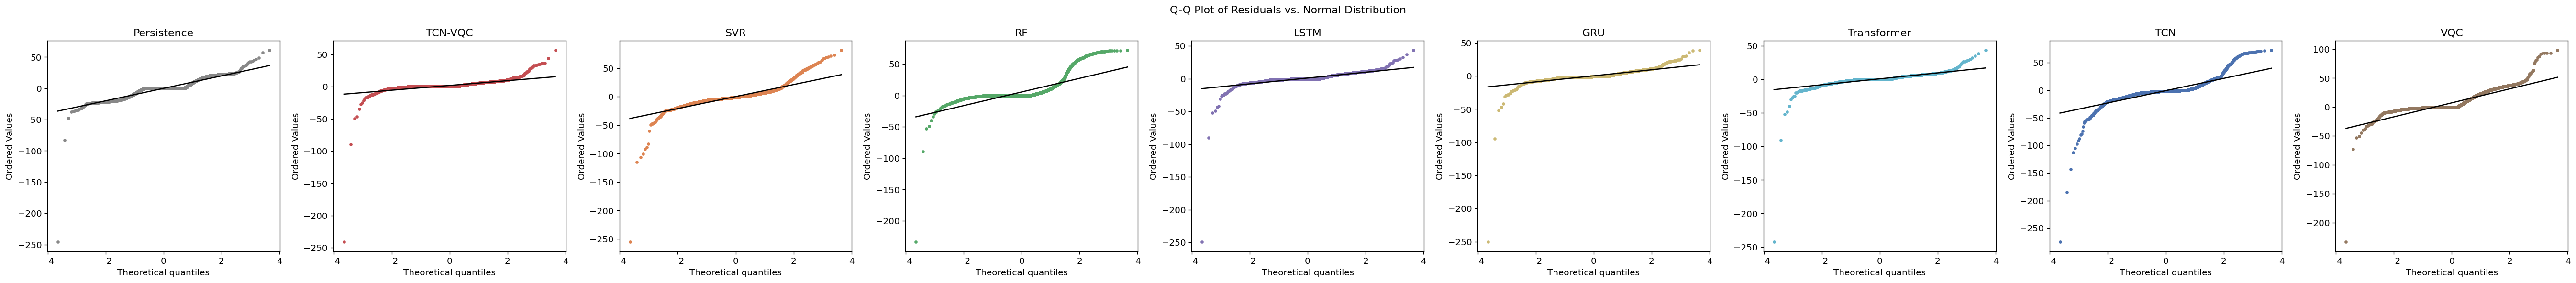

In [72]:
# --- Infographic 19: Q-Q Plot of Residuals (normality check) ---
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 5))
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    resid = y_true - y_pred
    stats.probplot(resid, dist="norm", plot=ax)
    ax.get_lines()[0].set_markerfacecolor(MODEL_COLORS[name])
    ax.get_lines()[0].set_markeredgecolor(MODEL_COLORS[name])
    ax.get_lines()[0].set_markersize(3)
    ax.get_lines()[1].set_color("black")
    ax.set_title(name)
fig.suptitle("Q-Q Plot of Residuals vs. Normal Distribution")
fig.tight_layout()
_savefig(fig, "info19_qq_plot")


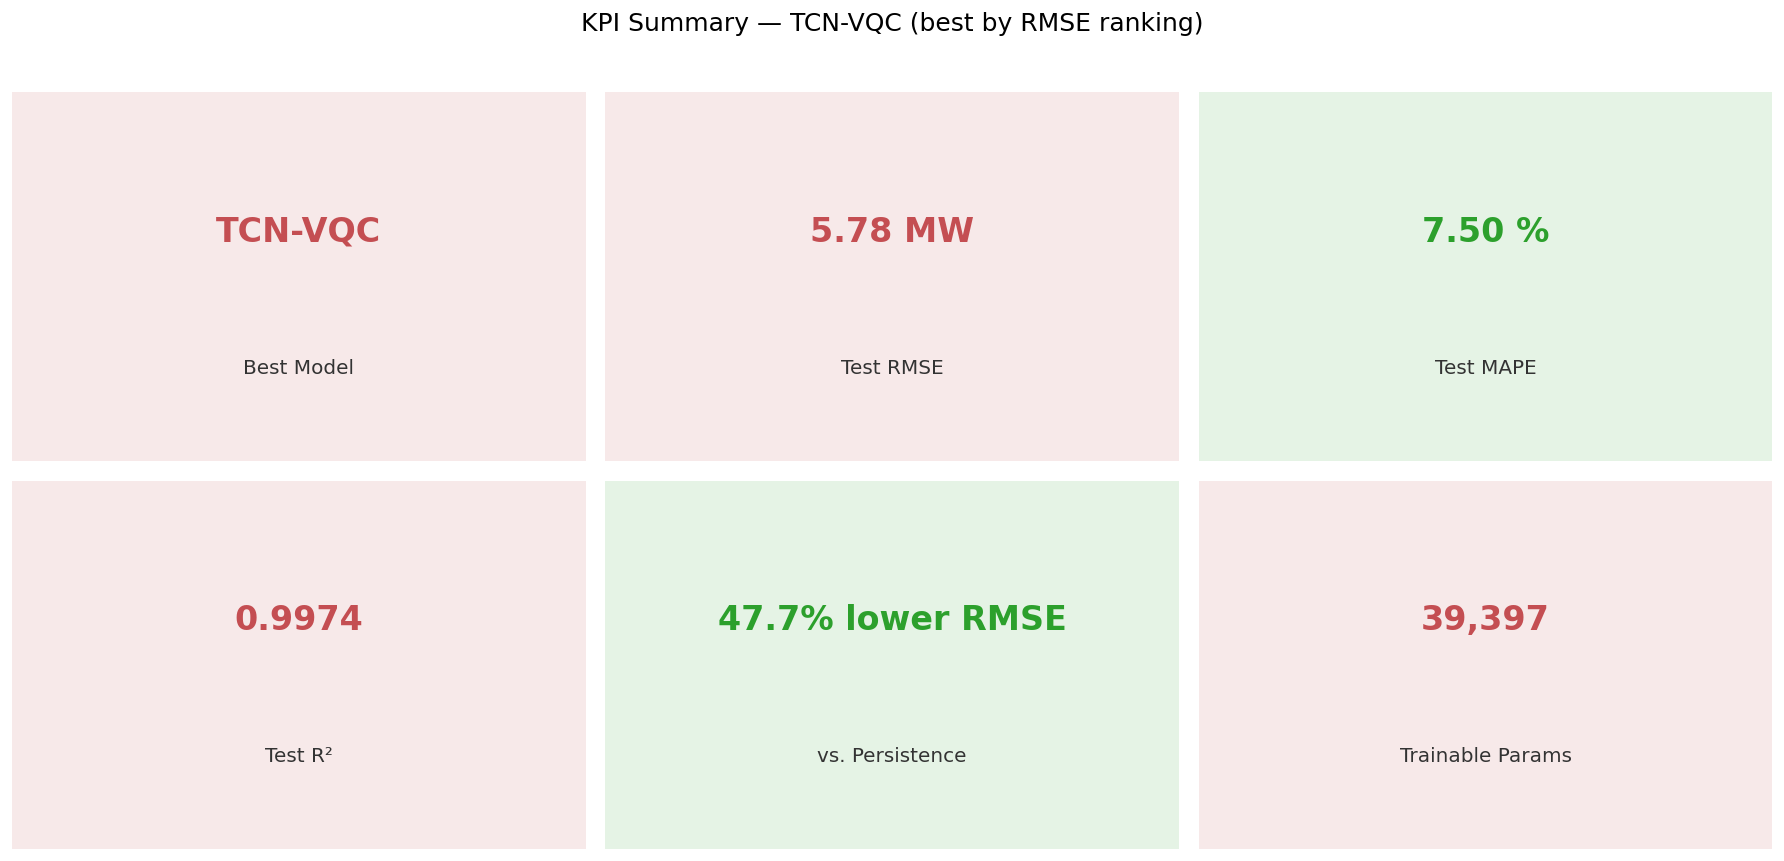

In [73]:
# --- Infographic 20: KPI Summary Dashboard ---
best_name = RANKED_DF.iloc[0]["Model"]
best = RESULTS[best_name]
persistence = RESULTS["Persistence"]
improve_vs_persistence = (1 - best["RMSE"] / persistence["RMSE"]) * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
cards = [
    ("Best Model", best_name, MODEL_COLORS[best_name]),
    ("Test RMSE", f"{best['RMSE']:.2f} MW", MODEL_COLORS[best_name]),
    ("Test MAPE", f"{best['MAPE_%']:.2f} %", "#2CA02C" if best["MAPE_%"] < 8 else "#C44E52"),
    ("Test R²", f"{best['R2']:.4f}", MODEL_COLORS[best_name]),
    ("vs. Persistence", f"{improve_vs_persistence:.1f}% lower RMSE", "#2CA02C"),
    ("Trainable Params", f"{best['Num_Params']:,}", MODEL_COLORS[best_name]),
]
for ax, (label, value, color) in zip(axes.ravel(), cards):
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor=color, alpha=0.12))
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=20, fontweight="bold", color=color)
    ax.text(0.5, 0.25, label, ha="center", va="center", fontsize=12, color="#333333")
fig.suptitle(f"KPI Summary — {best_name} (best by RMSE ranking)", fontsize=15, y=1.02)
fig.tight_layout()
_savefig(fig, "info20_kpi_dashboard")

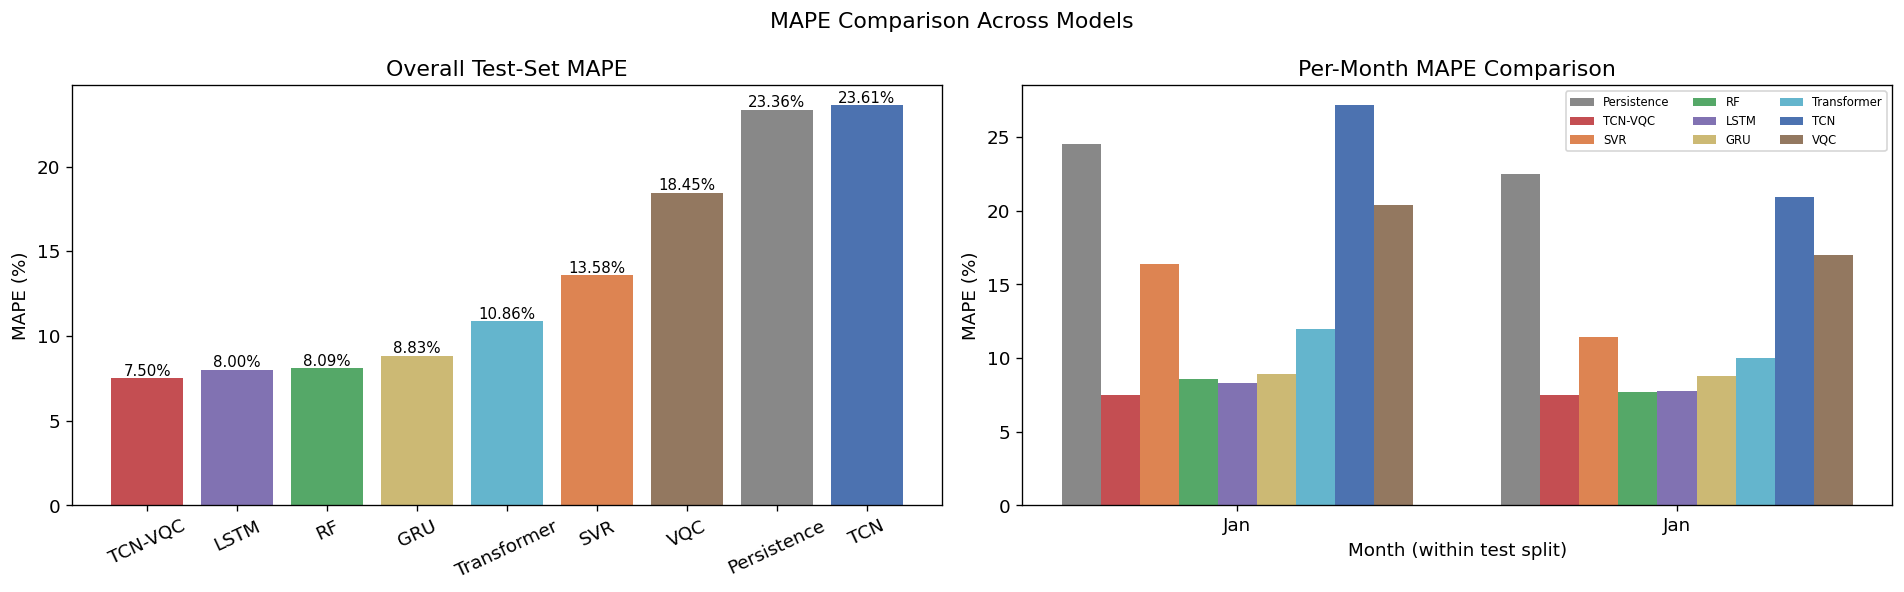

In [74]:
# --- MAPE comparison (overall + per-month) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: overall MAPE_% bar chart, ranked lowest-first (lower MAPE = better)
ax = axes[0]
ordered = METRICS_DF.sort_values("MAPE_%", ascending=True)
colors = [MODEL_COLORS[m] for m in ordered["Model"]]
bars = ax.bar(ordered["Model"], ordered["MAPE_%"], color=colors)
for b, v in zip(bars, ordered["MAPE_%"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("MAPE (%)")
ax.set_title("Overall Test-Set MAPE")
ax.tick_params(axis="x", rotation=25)

# Right: per-month MAPE_%, grouped bars (same layout as the per-month RMSE chart)
ax = axes[1]
n_models = len(RESULTS)
width = 0.8 / n_models  # NEW (comparison): scales automatically with however many models are in RESULTS
months_sorted = sorted(np.unique(DATA["test_months"]))
month_labels = [pd.Timestamp(2021, m, 1).strftime("%b") for m in months_sorted]
x = np.arange(len(months_sorted))
for i, name in enumerate(RESULTS.keys()):
    df_month = PER_MONTH_TABLES[name].set_index("Month").reindex(months_sorted)
    ax.bar(x + i * width, df_month["MAPE_%"], width=width, label=name, color=MODEL_COLORS[name])
ax.set_xticks(x + width * (n_models - 1) / 2)
ax.set_xticklabels(month_labels)
ax.set_xlabel("Month (within test split)")
ax.set_ylabel("MAPE (%)")
ax.set_title("Per-Month MAPE Comparison")
ax.legend(fontsize=7, ncol=3)

fig.suptitle("MAPE Comparison Across Models")
fig.tight_layout()
_savefig(fig, "mape_comparison")


## 18. Exports

In [75]:
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    pd.DataFrame({"y_true": y_true, "y_pred": y_pred}).to_csv(
        os.path.join(CFG.out_dir, "predictions", f"predictions_{name.replace(' ', '_')}.csv"), index=False
    )

with open(os.path.join(CFG.out_dir, "metrics", "config_used.json"), "w") as f:
    cfg_dict = {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.__dict__.items()}
    cfg_dict["seq_len"] = CFG.seq_len
    json.dump(cfg_dict, f, indent=2)

print("All outputs written under:", os.path.abspath(CFG.out_dir))
for sub in ["predictions", "metrics", "plots"]:
    d = os.path.join(CFG.out_dir, sub)
    print(f"  {d}/  -> {len(os.listdir(d))} files")


All outputs written under: c:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\outputs_power
  ./outputs_power\predictions/  -> 9 files
  ./outputs_power\metrics/  -> 13 files
  ./outputs_power\plots/  -> 28 files
